# Avance 7: Comparación de U-TAE y TSViT para Segmentación de Cultivos (PASTIS)

**Dataset:** PASTIS (series temporales Sentinel-2)
**Marco de Trabajo:** Metodología CRISP-ML(Q) — Fase de Modeling (comparación de arquitecturas) y Evaluation
**Equipo:** 13

---

## Tabla de Contenidos Metodológica

### 1. Configuración del Entorno y Acceso a los Datos
- Rutas del dataset, del modelo U-TAE del Avance 6 y de los pesos oficiales de TSViT; GPU y precisión.
- Particiones oficiales (folds 1–3 / 4 / 5) y codificación de las fechas.

### 2. Preparación de los Datos
- Misma normalización y mismos pesos de clase que el Avance 6.
- Ventanas de 24×24 generadas al vuelo desde los parches (sin duplicar el dataset).

### 3. Modelos
- U-TAE (copia exacta del Avance 6) y TSViT (Tarasiou et al., 2023), con la variante usada para entrenar desde cero.

### 4. Pérdida, Métricas e Inferencia por Ventanas
- Misma pérdida y mismas métricas que el Avance 6; reconstrucción del parche de 128×128 a partir de ventanas solapadas.

### 5. Entrenamiento de TSViT desde Cero
- Ajuste de memoria, bucle con checkpoints y reanudación, curvas de entrenamiento.

### 6. Validación (fold 4) y Fijación de la Configuración
- Mejor checkpoint y decisión sobre TTA; control de los pesos oficiales contra sus registros.

### 7. Evaluación con Datos No Vistos (fold 5) y Comparación
- Métricas de los tres modelos, IoU por clase, matrices de confusión, ejemplos visuales e intervalos bootstrap por parche.

### 8. Conclusiones Metodológicas CRISP-ML(Q)

### Declaración sobre el uso de herramientas de inteligencia artificial

## 1. Configuración del Entorno y Acceso a los Datos

En el Avance 6, **U-TAE** (convoluciones + atención temporal ligera) alcanzó en el fold 5 un mIoU de **0.6424** sobre parches completos. El objetivo de este avance es compararlo con **TSViT** (*Temporo-Spatial Vision Transformer*), que en el artículo original supera a U-TAE en PASTIS por unos 2 puntos de mIoU (65.9 % frente a 63.1 %). Esa ventaja se toma aquí como **hipótesis**, no como un hecho.

Se comparan tres modelos sobre exactamente los mismos parches y con las mismas métricas:

| Modelo | Origen | Qué mide |
|---|---|---|
| **U-TAE** | Avance 6 (`salidas_utae/utae_ckpt/best.pt`) | Referencia del proyecto |
| **TSViT (pesos oficiales)** | Checkpoint `TSViT_fold1` de los autores (train folds 1–3, validación 4, prueba 5) | TSViT tal como se publicó |
| **TSViT (desde cero)** | Entrenado en este notebook con el pipeline del Avance 6 | Arquitectura con las mismas condiciones de entrenamiento que U-TAE |

Se mantienen las reglas de evaluación de los avances anteriores: el fold 5 solo se usa al final, con todo fijado con el fold 4; Void (19) se ignora; Fondo (0) cuenta en las métricas.

In [ ]:
# ==============================================================================
# 1.1 CONFIGURACIÓN DEL ENTORNO, LIBRERÍAS Y PARÁMETROS
# ==============================================================================
import os
import sys
import json
import glob
import time
import math
import copy
import random
import platform
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import einsum
from tqdm.auto import tqdm
from einops import rearrange, repeat
from einops.layers.torch import Rearrange

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# ------------------------------------------------------------------------------
# RUTAS
# ------------------------------------------------------------------------------
# True -> prueba de humo (pocos parches y 2 épocas). En ese modo la "prueba" usa parches del fold 4,
# de modo que el fold 5 no se toca.
MODO_RAPIDO = os.environ.get("MODO_RAPIDO", "0") == "1"
RUTA_LOCAL_PASTIS = r"C:\Users\lalo4\Downloads\PASTIS\PASTIS"
RUTA_AVANCE6 = Path(r"C:\Users\lalo4\Downloads\Avances\salidas_utae")            # normalizacion.json y utae_ckpt/best.pt
RUTA_TSVIT_OFICIAL = Path(r"C:\Users\lalo4\Downloads\Avances\externos\TSViT_PASTIS24_oficial\root"
                          r"\streaming-inference\temp\personal\tsvit\PASTIS24_checkpoints\TSViT_fold1\best.pth")

# ------------------------------------------------------------------------------
# HIPERPARÁMETROS DE TSViT (configs/PASTIS24/TSViT_fold1.yaml) Y DEL PIPELINE DEL AVANCE 6
# ------------------------------------------------------------------------------
EPOCHS          = 100       # yaml: num_epochs
WARMUP_EPOCHS   = 10        # yaml: num_warmup_epochs (calentamiento lineal)
LR              = 1e-3      # yaml: lr_base
LR_INICIO       = 1e-8      # yaml: lr_start
LR_MIN          = 5e-6      # yaml: lr_min (coseno)
WEIGHT_DECAY    = 0.0       # yaml: weight_decay
EFFECTIVE_BATCH = 16        # yaml: batch_size de entrenamiento
MAX_SEQ_LEN     = 60        # yaml: max_seq_len
VENTANA         = 24        # yaml: img_res (PASTIS24)
VENTANAS_POR_PARCHE = 25    # igual que PASTIS24 (25 ventanas por parche y época)
BUFFER_PARCHES  = 32        # parches en memoria a la vez para mezclar ventanas
PATIENCE        = 30        # Avance 6
DICE_WEIGHT     = 1.0       # Avance 6
PESO_MIN, PESO_MAX = 0.2, 8.0   # Avance 6
N_PARCHES_NORM  = 150       # Avance 6
GRAD_CLIP       = 1.0       # Avance 6
EVALUAR_PRUEBA  = True
PROBAR_TTA      = True
N_BOOTSTRAP     = 2000
SEED            = 42

NUM_CLASSES = 19
VOID_LABEL  = 19
REFERENCE_DATE = datetime(2018, 9, 1)
OFFSETS_SOLAPE = [0, 21, 42, 62, 83, 104]   # 6 ventanas por eje: cubren los 128 px con solape
OFFSETS_REJILLA = [0, 24, 48, 72, 96]       # rejilla de PASTIS24 (sin solape, no cubre las filas/columnas 120-127)

if MODO_RAPIDO:
    EPOCHS, WARMUP_EPOCHS, PATIENCE, N_BOOTSTRAP = 2, 1, 5, 200
    MAX_PATCHES = {"train": 24, "val": 8, "test": 8}
else:
    MAX_PATCHES = {"train": None, "val": None, "test": None}

NOMBRES_CLASES = {
    0: "Fondo", 1: "Pradera", 2: "Trigo blando de invierno", 3: "Maíz",
    4: "Cebada de invierno", 5: "Colza de invierno", 6: "Cebada de primavera",
    7: "Girasol", 8: "Vid", 9: "Remolacha", 10: "Triticale de invierno",
    11: "Trigo duro de invierno", 12: "Frutas, hortalizas y flores", 13: "Papa",
    14: "Forraje leguminoso", 15: "Soya", 16: "Huerto", 17: "Cereal mixto",
    18: "Sorgo",
}

WORK_DIR = Path(os.environ.get("TSVIT_WORK_DIR", "salidas_tsvit"))
CKPT_DIR = WORK_DIR / ("tsvit_ckpt_rapido" if MODO_RAPIDO else "tsvit_ckpt")
CKPT_DIR.mkdir(parents=True, exist_ok=True)

def fijar_semillas(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
fijar_semillas(SEED)

for ruta in (RUTA_AVANCE6 / "utae_ckpt" / "best.pt", RUTA_AVANCE6 / "normalizacion.json", RUTA_TSVIT_OFICIAL):
    if not Path(ruta).is_file():
        raise FileNotFoundError(f"No se encontró {ruta}")

print("=== VERIFICACIÓN DEL ENTORNO ===")
print("Python", platform.python_version(), "| torch", torch.__version__, "| numpy", np.__version__)
print("Modo rápido:", MODO_RAPIDO, "| Épocas:", EPOCHS)
print("Carpeta de trabajo:", WORK_DIR.resolve())
print("Checkpoints de TSViT en:", CKPT_DIR.resolve())

=== VERIFICACIÓN DEL ENTORNO ===
Python 3.12.16 | torch 2.5.1+cu121 | numpy 2.5.4
Modo rápido: False | Épocas: 100
Carpeta de trabajo: C:\Users\lalo4\Downloads\Avances\salidas_tsvit
Checkpoints de TSViT en: C:\Users\lalo4\Downloads\Avances\salidas_tsvit\tsvit_ckpt


In [ ]:
# ==============================================================================
# 1.2 GPU, MEMORIA Y PRECISIÓN NUMÉRICA
# ==============================================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VRAM_GB, AMP_DTYPE = 0.0, None
if DEVICE.type == "cuda":
    prop = torch.cuda.get_device_properties(0)
    VRAM_GB = prop.total_memory / 1024 ** 3
    cc = torch.cuda.get_device_capability(0)
    print(f"GPU: {prop.name} | VRAM: {VRAM_GB:.1f} GB | compute capability {cc[0]}.{cc[1]}")
    AMP_DTYPE = torch.bfloat16 if (torch.cuda.is_bf16_supported() and cc[0] >= 8) else torch.float16
    torch.backends.cudnn.benchmark = True
else:
    print("AVISO: no hay GPU. El entrenamiento completo sería extremadamente lento.")
USE_AMP = AMP_DTYPE is not None
print("Precisión mixta:", AMP_DTYPE if USE_AMP else "desactivada")

def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE or torch.float32, enabled=USE_AMP)

GPU: NVIDIA GeForce RTX 4050 Laptop GPU | VRAM: 6.0 GB | compute capability 8.9
Precisión mixta: torch.bfloat16


In [ ]:
# ==============================================================================
# 1.3 DATASET, PARTICIONES OFICIALES Y FECHAS
# ==============================================================================
PASTIS_ROOT = Path(os.environ.get("PASTIS_ROOT", RUTA_LOCAL_PASTIS))
assert (PASTIS_ROOT / "metadata.geojson").is_file(), f"No se encontró PASTIS en {PASTIS_ROOT}"

def ruta_s2(pid):
    return PASTIS_ROOT / "DATA_S2" / f"S2_{pid}.npy"

def ruta_target(pid):
    return PASTIS_ROOT / "ANNOTATIONS" / f"TARGET_{pid}.npy"

with open(PASTIS_ROOT / "metadata.geojson", "r") as f:
    geojson = json.load(f)
metadata = pd.DataFrame([ft["properties"] for ft in geojson["features"]])
metadata["ID_PATCH"] = metadata["ID_PATCH"].astype(int)

def fechas_ordenadas(valor):
    if isinstance(valor, str):
        valor = json.loads(valor)
    return [datetime.strptime(str(valor[k]), "%Y%m%d") for k in sorted(valor, key=lambda x: int(x))]

FECHAS = {int(r["ID_PATCH"]): fechas_ordenadas(r["dates-S2"]) for _, r in metadata.iterrows()}
# U-TAE y TSViT (desde cero): días desde 2018-09-01, en orden cronológico.
DATES = {p: np.array([(f - REFERENCE_DATE).days for f in fs], dtype=np.int64) for p, fs in FECHAS.items()}
# TSViT oficial: día del año (1-366), como en data/PASTIS24/data2windows.py.
DOY = {p: np.array([f.timetuple().tm_yday for f in fs], dtype=np.int64) for p, fs in FECHAS.items()}

def tomar(df, n):
    ids = sorted(df["ID_PATCH"].astype(int).tolist())
    if n is not None and n < len(ids):
        ids = sorted(np.random.default_rng(SEED).choice(ids, n, replace=False).tolist())
    return ids

FOLDS_COMPLETOS = {"train": metadata[metadata["Fold"].isin([1, 2, 3])],
                   "val": metadata[metadata["Fold"] == 4],
                   "test": metadata[metadata["Fold"] == 5]}
IDS = {k: tomar(v, MAX_PATCHES[k]) for k, v in FOLDS_COMPLETOS.items()}
if MODO_RAPIDO:
    # Prueba de humo: la "prueba" se hace con otros parches del fold 4 para no tocar el fold 5.
    resto_val = [p for p in sorted(FOLDS_COMPLETOS["val"]["ID_PATCH"].astype(int)) if p not in IDS["val"]]
    IDS["test"] = resto_val[:MAX_PATCHES["test"]]
assert set(IDS["train"]).isdisjoint(IDS["val"]) and set(IDS["train"]).isdisjoint(IDS["test"])
assert set(IDS["val"]).isdisjoint(IDS["test"])

dias_todos = np.concatenate([DATES[p] for p in metadata["ID_PATCH"]])
doy_rep = sum(len(set(DOY[p])) < len(DOY[p]) for p in metadata["ID_PATCH"])
print("Distribución de folds:", metadata["Fold"].value_counts().sort_index().to_dict())
print("Parches usados:", {k: len(v) for k, v in IDS.items()}, "(MODO_RAPIDO: prueba = fold 4)" if MODO_RAPIDO else "")
print(f"Fechas: {min(min(f) for f in FECHAS.values()).date()} a {max(max(f) for f in FECHAS.values()).date()} | "
      f"días desde 2018-09-01: {dias_todos.min()}-{dias_todos.max()}")
print(f"Parches con días del año (DOY) repetidos: {doy_rep} de {len(metadata)} "
      "(fechas de 2018 y 2019 con el mismo DOY)")
print("Parches con más de", MAX_SEQ_LEN, "fechas:", sum(len(DATES[p]) > MAX_SEQ_LEN for p in metadata["ID_PATCH"]))

Distribución de folds: {1: 487, 2: 494, 3: 474, 4: 482, 5: 496}
Parches usados: {'train': 1455, 'val': 482, 'test': 496} 
Fechas: 2018-09-17 a 2019-10-27 | días desde 2018-09-01: 16-421
Parches con días del año (DOY) repetidos: 2433 de 2433 (fechas de 2018 y 2019 con el mismo DOY)
Parches con más de 60 fechas: 623


**Fechas.** El TSViT publicado representa cada adquisición por su **día del año** (DOY, 1–366). Las series de PASTIS van de septiembre de 2018 a octubre de 2019, de modo que, en todos los parches, adquisiciones de otoño de 2018 y de otoño de 2019 reciben el mismo código temporal. U-TAE usa los **días transcurridos desde el 1 de septiembre de 2018**, que no tienen esa ambigüedad. Para que la comparación entre arquitecturas no dependa de esa diferencia, el TSViT entrenado desde cero en este notebook usa la misma referencia que U-TAE (sección 3). Los pesos oficiales se evalúan con su codificación original, porque así fueron entrenados.

## 2. Preparación de los Datos

**Normalización y pesos de clase.** Se reutilizan exactamente los del Avance 6: la media y desviación por banda se leen de `salidas_utae/normalizacion.json`, y los pesos `1/√frecuencia` (normalizados y acotados a `[0.2, 8]`) se recalculan con el mismo código y se comparan con los guardados en el checkpoint de U-TAE.

In [ ]:
# ==============================================================================
# 2.1 NORMALIZACIÓN (AVANCE 6) Y PESOS DE CLASE
# ==============================================================================
_n = json.loads((RUTA_AVANCE6 / "normalizacion.json").read_text())
MEAN, STD = np.array(_n["mean"], np.float32), np.array(_n["std"], np.float32)
ids_train_completos = sorted(FOLDS_COMPLETOS["train"]["ID_PATCH"].astype(int).tolist())
firma_esperada = f"{SEED}|{N_PARCHES_NORM}|{len(ids_train_completos)}|{ids_train_completos[:5]}"
assert _n.get("firma") == firma_esperada, "normalizacion.json no corresponde a la corrida completa del Avance 6"
print("Normalización del Avance 6 cargada (firma verificada).")

conteo = np.zeros(NUM_CLASSES + 1, np.int64)
for pid in tqdm(ids_train_completos, desc="Frecuencias de clase"):
    y = np.load(ruta_target(pid))[0].astype(np.int64)
    conteo += np.bincount(y.ravel(), minlength=NUM_CLASSES + 1)
validos = conteo[:NUM_CLASSES].astype(np.float64)
freq = validos / validos.sum()
pesos = np.where(freq > 0, 1.0 / np.sqrt(np.maximum(freq, 1e-12)), 0.0)
pesos = pesos / pesos[freq > 0].mean()
pesos = np.where(freq > 0, np.clip(pesos, PESO_MIN, PESO_MAX), 0.0)
CLASS_WEIGHTS = torch.tensor(pesos, dtype=torch.float32)

ck_utae = torch.load(RUTA_AVANCE6 / "utae_ckpt" / "best.pt", map_location="cpu", weights_only=False)
assert np.allclose(np.asarray(ck_utae["class_weights"]), pesos), "Los pesos de clase no coinciden con el Avance 6"
assert np.allclose(np.asarray(ck_utae["mean"]), MEAN) and np.allclose(np.asarray(ck_utae["std"]), STD)
display(pd.DataFrame({"Banda": ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"],
                      "Media": MEAN.round(1), "Desv. estándar": STD.round(1)}).T)
print("Pesos de clase idénticos a los del checkpoint de U-TAE:", np.round(pesos, 3).tolist())

Normalización del Avance 6 cargada (firma verificada).


Frecuencias de clase:   0%|          | 0/1455 [00:00<?, ?it/s]

,0,1,2,3,4,5,6,7,8,9
Banda,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12
Media,1161.400024,1378.300049,1446.699951,1777.300049,2697.0,3029.699951,3168.5,3283.899902,2446.199951,1661.0
Desv. estándar,2043.0,1983.699951,2057.399902,1969.599976,1875.199951,1892.099976,1905.5,1894.699951,1563.599976,1395.900024


Pesos de clase idénticos a los del checkpoint de U-TAE: [0.2, 0.256, 0.422, 0.364, 0.773, 0.824, 1.397, 1.129, 0.636, 1.235, 1.25, 1.043, 1.11, 2.025, 0.872, 1.007, 1.044, 1.574, 1.865]


### 2.2 Ventanas de 24×24 generadas al vuelo

TSViT trabaja con ventanas de 24×24 píxeles (PASTIS24). En lugar de crear los ~60 mil archivos *pickle* del repositorio original, las ventanas se recortan en memoria a partir de los mismos `.npy` del Avance 6:

- **Entrenamiento:** en cada época los parches se recorren en orden aleatorio, en bloques de `BUFFER_PARCHES`. De cada parche se extraen `VENTANAS_POR_PARCHE` ventanas en posiciones aleatorias (lo que también aprovecha las filas y columnas 120–127, que PASTIS24 nunca usa), cada una con una de las 8 transformaciones diédricas (rotaciones y giros, como en U-TAE). Las ventanas del bloque se mezclan antes de formar los lotes. Como en el código original, se descartan las ventanas sin ningún píxel etiquetado.
- **Fechas:** se conservan como máximo `MAX_SEQ_LEN = 60` fechas. En entrenamiento, si el parche tiene 61, se eligen 60 al azar manteniendo el orden; en validación y prueba se toman las 60 primeras. Las series más cortas se rellenan con ceros hasta 60, con día 0 como código de relleno (igual que el original, que no usa máscara de relleno).
- **Validación y prueba:** el parche completo de 128×128 se cubre con 6×6 ventanas solapadas (`OFFSETS_SOLAPE`) y se promedian las probabilidades donde se superponen.

In [ ]:
# ==============================================================================
# 2.2 CARGA DE PARCHES Y GENERADOR DE LOTES DE VENTANAS
# ==============================================================================
MEAN4, STD4 = MEAN.reshape(1, 10, 1, 1), STD.reshape(1, 10, 1, 1)

def cargar_parche(pid, rng=None):
    """Devuelve x (T', 10, 128, 128) normalizado, días (T',) y etiqueta (128, 128) con T' <= MAX_SEQ_LEN."""
    x = np.load(ruta_s2(pid))
    d = DATES[pid]
    T = len(d)
    if T > MAX_SEQ_LEN:
        idx = np.sort(rng.choice(T, MAX_SEQ_LEN, replace=False)) if rng is not None else np.arange(MAX_SEQ_LEN)
        x, d = x[idx], d[idx]
    x = (x.astype(np.float32) - MEAN4) / STD4
    y = np.load(ruta_target(pid))[0].astype(np.int64)
    return x, d, y

def a_tensor_ventanas(xs, ds):
    """Lista de ventanas (T_i, 10, 24, 24) -> tensor (B, 60, 24, 24, 10) y días (B, 60), con relleno en cero."""
    B = len(xs)
    xt = torch.zeros(B, MAX_SEQ_LEN, VENTANA, VENTANA, 10)
    dt = torch.zeros(B, MAX_SEQ_LEN, dtype=torch.long)
    for i, (x, d) in enumerate(zip(xs, ds)):
        xt[i, :x.shape[0]] = torch.from_numpy(np.ascontiguousarray(x)).permute(0, 2, 3, 1)
        dt[i, :len(d)] = torch.from_numpy(d)
    return xt, dt

def lotes_entrenamiento(ids, batch_size, rng):
    orden = list(rng.permutation(ids))
    pendientes = []
    for i in range(0, len(orden), BUFFER_PARCHES):
        muestras = []
        for pid in orden[i:i + BUFFER_PARCHES]:
            x, d, y = cargar_parche(int(pid), rng)
            for _ in range(VENTANAS_POR_PARCHE):
                r, c = rng.integers(0, 128 - VENTANA + 1, size=2)
                yv = y[r:r + VENTANA, c:c + VENTANA]
                if (yv == VOID_LABEL).all():
                    continue
                xv = x[:, :, r:r + VENTANA, c:c + VENTANA]
                k = int(rng.integers(4))
                xv, yv = np.rot90(xv, k, axes=(2, 3)), np.rot90(yv, k)
                if rng.random() < 0.5:
                    xv, yv = xv[..., ::-1], yv[..., ::-1]
                muestras.append((xv, d, np.ascontiguousarray(yv)))
        muestras = pendientes + [muestras[j] for j in rng.permutation(len(muestras))]
        n_completos = len(muestras) // batch_size * batch_size
        for j in range(0, n_completos, batch_size):
            lote = muestras[j:j + batch_size]
            xt, dt = a_tensor_ventanas([m[0] for m in lote], [m[1] for m in lote])
            yt = torch.from_numpy(np.stack([m[2] for m in lote]))
            yield xt, dt, yt
        pendientes = muestras[n_completos:]

PASOS_POR_EPOCA = (VENTANAS_POR_PARCHE * len(IDS["train"])) // EFFECTIVE_BATCH   # nominal, para el learning rate
_x, _d, _y = next(lotes_entrenamiento(IDS["train"][:2], 4, np.random.default_rng(0)))
print("Lote de ejemplo: x", tuple(_x.shape), "| días", tuple(_d.shape), "| y", tuple(_y.shape))
print(f"x normalizada: media={_x[_d > 0].mean():.2f}, desv={_x[_d > 0].std():.2f} | días: {_d[0, :5].tolist()} ...")
print("Pasos nominales por época (lote efectivo", EFFECTIVE_BATCH, "):", PASOS_POR_EPOCA)

Lote de ejemplo: x (4, 60, 24, 24, 10) | días (4, 60) | y (4, 24, 24)
x normalizada: media=0.09, desv=0.90 | días: [23, 28, 33, 38, 48] ...
Pasos nominales por época (lote efectivo 16 ): 2273


## 3. Modelos

**U-TAE.** La celda 3.1 es una copia exacta de la implementación del Avance 6 (repositorio oficial `VSainteuf/utae-paps`, licencia MIT); se usa solo para cargar `best.pt` y volver a evaluarlo, sin reentrenarlo.

**TSViT.** La celda 3.2 reproduce `models/TSViT/TSViTdense.py` y `module.py` del repositorio oficial [michaeltrs/DeepSatModels](https://github.com/michaeltrs/DeepSatModels) (licencia Apache 2.0, commit `53e6559`). El modelo divide cada ventana de 24×24 en parches de 2×2; primero un *transformer* temporal procesa la serie de cada parche junto con 19 *tokens* de clase y la codificación de la fecha; después un *transformer* espacial relaciona los 144 parches de la ventana para cada clase. Se incluyen tres detalles verificados:

1. **Reconstrucción espacial.** En junio de 2026 el repositorio corrigió cómo se vuelven a colocar los parches 2×2 en la imagen de salida (commits `d89f57b` y `a9d20fd`). Los pesos oficiales disponibles en el Drive del README se entrenaron **con la versión anterior** (commit `0bc3d10`); con la versión corregida su mIoU en el fold 4 cae de 0.666 a ≈0.40. Por eso la clase admite `legacy_reshape=True` para los pesos oficiales y usa la versión corregida para entrenar desde cero.
2. **Atención.** La única modificación de eficiencia es usar `F.scaled_dot_product_attention`, que calcula lo mismo que el original sin materializar la matriz de atención. Se comprobó con los pesos oficiales: diferencia máxima de 7.6×10⁻⁵ en los logits y predicciones idénticas. Con la atención original, un lote de 16 no cabía en 6 GB.
3. **Fechas (`TSViTDias`).** Para el entrenamiento desde cero, el one-hot del día del año (366 valores) se sustituye por el one-hot de los días desde 2018-09-01 (430 valores, el 0 reservado para el relleno). Es la única diferencia de arquitectura respecto al original y añade ≈8 mil parámetros.

In [ ]:
# ==============================================================================
# 3.1 IMPLEMENTACIÓN DE U-TAE — COPIA EXACTA DE LA CELDA 3.1 DEL AVANCE 6 (adaptada de VSainteuf/utae-paps, licencia MIT)
# ==============================================================================
# MIT License — Copyright (c) Vivien Sainte Fare Garnot. Ver github.com/VSainteuf/utae-paps

class PositionalEncoder(nn.Module):
    def __init__(self, d, T=1000, repeat=None, offset=0):
        super().__init__()
        self.d, self.T, self.repeat = d, T, repeat
        self.denom = torch.pow(T, 2 * (torch.arange(offset, offset + d).float() // 2) / d)
        self.updated_location = False

    def forward(self, batch_positions):
        if not self.updated_location:
            self.denom = self.denom.to(batch_positions.device)
            self.updated_location = True
        sinusoid_table = batch_positions[:, :, None] / self.denom[None, None, :]   # B x T x C
        sinusoid_table[:, :, 0::2] = torch.sin(sinusoid_table[:, :, 0::2])
        sinusoid_table[:, :, 1::2] = torch.cos(sinusoid_table[:, :, 1::2])
        if self.repeat is not None:
            sinusoid_table = torch.cat([sinusoid_table for _ in range(self.repeat)], dim=-1)
        return sinusoid_table


class ScaledDotProductAttention(nn.Module):
    def __init__(self, temperature, attn_dropout=0.1):
        super().__init__()
        self.temperature = temperature
        self.dropout = nn.Dropout(attn_dropout)
        self.softmax = nn.Softmax(dim=2)

    def forward(self, q, k, v, pad_mask=None):
        attn = torch.matmul(q.unsqueeze(1), k.transpose(1, 2)) / self.temperature
        if pad_mask is not None:
            attn = attn.masked_fill(pad_mask.unsqueeze(1), -1e3)
        attn = self.dropout(self.softmax(attn))
        return torch.matmul(attn, v), attn


class MultiHeadAttention(nn.Module):
    def __init__(self, n_head, d_k, d_in):
        super().__init__()
        self.n_head, self.d_k, self.d_in = n_head, d_k, d_in
        self.Q = nn.Parameter(torch.zeros((n_head, d_k))).requires_grad_(True)
        nn.init.normal_(self.Q, mean=0, std=np.sqrt(2.0 / d_k))
        self.fc1_k = nn.Linear(d_in, n_head * d_k)
        nn.init.normal_(self.fc1_k.weight, mean=0, std=np.sqrt(2.0 / d_k))
        self.attention = ScaledDotProductAttention(temperature=np.power(d_k, 0.5))

    def forward(self, v, pad_mask=None):
        d_k, d_in, n_head = self.d_k, self.d_in, self.n_head
        sz_b, seq_len, _ = v.size()
        q = torch.stack([self.Q for _ in range(sz_b)], dim=1).view(-1, d_k)        # (n*b) x d_k
        k = self.fc1_k(v).view(sz_b, seq_len, n_head, d_k)
        k = k.permute(2, 0, 1, 3).contiguous().view(-1, seq_len, d_k)               # (n*b) x lk x dk
        if pad_mask is not None:
            pad_mask = pad_mask.repeat((n_head, 1))
        v = torch.stack(v.split(v.shape[-1] // n_head, dim=-1)).view(n_head * sz_b, seq_len, -1)
        output, attn = self.attention(q, k, v, pad_mask=pad_mask)
        attn = attn.view(n_head, sz_b, 1, seq_len).squeeze(dim=2)
        output = output.view(n_head, sz_b, 1, d_in // n_head).squeeze(dim=2)
        return output, attn


class LTAE2d(nn.Module):
    def __init__(self, in_channels=128, n_head=16, d_k=4, mlp=[256, 128], dropout=0.2,
                 d_model=256, T=1000, return_att=False, positional_encoding=True):
        super().__init__()
        self.in_channels, self.mlp, self.return_att, self.n_head = in_channels, copy.deepcopy(mlp), return_att, n_head
        if d_model is not None:
            self.d_model = d_model
            self.inconv = nn.Conv1d(in_channels, d_model, 1)
        else:
            self.d_model, self.inconv = in_channels, None
        assert self.mlp[0] == self.d_model
        self.positional_encoder = (PositionalEncoder(self.d_model // n_head, T=T, repeat=n_head)
                                   if positional_encoding else None)
        self.attention_heads = MultiHeadAttention(n_head=n_head, d_k=d_k, d_in=self.d_model)
        self.in_norm = nn.GroupNorm(num_groups=n_head, num_channels=self.in_channels)
        self.out_norm = nn.GroupNorm(num_groups=n_head, num_channels=mlp[-1])
        layers = []
        for i in range(len(self.mlp) - 1):
            layers.extend([nn.Linear(self.mlp[i], self.mlp[i + 1]), nn.BatchNorm1d(self.mlp[i + 1]), nn.ReLU()])
        self.mlp = nn.Sequential(*layers)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, batch_positions=None, pad_mask=None):
        sz_b, seq_len, d, h, w = x.shape
        if pad_mask is not None:
            pad_mask = pad_mask.unsqueeze(-1).repeat((1, 1, h)).unsqueeze(-1).repeat((1, 1, 1, w))   # BxTxHxW
            pad_mask = pad_mask.permute(0, 2, 3, 1).contiguous().view(sz_b * h * w, seq_len)
        out = x.permute(0, 3, 4, 1, 2).contiguous().view(sz_b * h * w, seq_len, d)
        out = self.in_norm(out.permute(0, 2, 1)).permute(0, 2, 1)
        if self.inconv is not None:
            out = self.inconv(out.permute(0, 2, 1)).permute(0, 2, 1)
        if self.positional_encoder is not None:
            bp = batch_positions.unsqueeze(-1).repeat((1, 1, h)).unsqueeze(-1).repeat((1, 1, 1, w))
            bp = bp.permute(0, 2, 3, 1).contiguous().view(sz_b * h * w, seq_len)
            out = out + self.positional_encoder(bp)
        out, attn = self.attention_heads(out, pad_mask=pad_mask)
        out = out.permute(1, 0, 2).contiguous().view(sz_b * h * w, -1)             # concatena cabezas
        out = self.dropout(self.mlp(out))
        out = self.out_norm(out) if self.out_norm is not None else out
        out = out.view(sz_b, h, w, -1).permute(0, 3, 1, 2)
        attn = attn.view(self.n_head, sz_b, h, w, seq_len).permute(0, 1, 4, 2, 3)   # head x b x t x h x w
        return (out, attn) if self.return_att else out


class TemporallySharedBlock(nn.Module):
    # Aplica el mismo bloque convolucional a todas las fechas (B*T imágenes), sin procesar las de relleno.
    def __init__(self, pad_value=None):
        super().__init__()
        self.pad_value = pad_value

    def smart_forward(self, input):
        if input.dim() == 4:
            return self.forward(input)
        b, t, c, h, w = input.shape
        out = input.reshape(b * t, c, h, w)
        if self.pad_value is not None:
            pad_mask = (out == self.pad_value).all(dim=-1).all(dim=-1).all(dim=-1)
            if pad_mask.any():
                # Cambio respecto al original: sin pasada extra sobre ceros para conocer la forma de salida.
                validas = self.forward(out[~pad_mask])
                temp = validas.new_full((b * t,) + tuple(validas.shape[1:]), float(self.pad_value))
                temp[~pad_mask] = validas
                out = temp
            else:
                out = self.forward(out)
        else:
            out = self.forward(out)
        return out.view(b, t, *out.shape[1:])


class ConvLayer(nn.Module):
    def __init__(self, nkernels, norm="batch", k=3, s=1, p=1, n_groups=4, last_relu=True, padding_mode="reflect"):
        super().__init__()
        layers = []
        if norm == "batch":
            nl = nn.BatchNorm2d
        elif norm == "instance":
            nl = nn.InstanceNorm2d
        elif norm == "group":
            nl = lambda num_feats: nn.GroupNorm(num_channels=num_feats, num_groups=n_groups)
        else:
            nl = None
        for i in range(len(nkernels) - 1):
            layers.append(nn.Conv2d(nkernels[i], nkernels[i + 1], kernel_size=k, padding=p, stride=s,
                                    padding_mode=padding_mode))
            if nl is not None:
                layers.append(nl(nkernels[i + 1]))
            if last_relu or i < len(nkernels) - 2:
                layers.append(nn.ReLU())
        self.conv = nn.Sequential(*layers)

    def forward(self, input):
        return self.conv(input)


class ConvBlock(TemporallySharedBlock):
    def __init__(self, nkernels, pad_value=None, norm="batch", last_relu=True, padding_mode="reflect"):
        super().__init__(pad_value=pad_value)
        self.conv = ConvLayer(nkernels=nkernels, norm=norm, last_relu=last_relu, padding_mode=padding_mode)

    def forward(self, input):
        return self.conv(input)


class DownConvBlock(TemporallySharedBlock):
    def __init__(self, d_in, d_out, k, s, p, pad_value=None, norm="batch", padding_mode="reflect"):
        super().__init__(pad_value=pad_value)
        self.down = ConvLayer(nkernels=[d_in, d_in], norm=norm, k=k, s=s, p=p, padding_mode=padding_mode)
        self.conv1 = ConvLayer(nkernels=[d_in, d_out], norm=norm, padding_mode=padding_mode)
        self.conv2 = ConvLayer(nkernels=[d_out, d_out], norm=norm, padding_mode=padding_mode)

    def forward(self, input):
        out = self.conv1(self.down(input))
        return out + self.conv2(out)


class UpConvBlock(nn.Module):
    def __init__(self, d_in, d_out, k, s, p, norm="batch", d_skip=None, padding_mode="reflect"):
        super().__init__()
        d = d_out if d_skip is None else d_skip
        self.skip_conv = nn.Sequential(nn.Conv2d(d, d, kernel_size=1), nn.BatchNorm2d(d), nn.ReLU())
        self.up = nn.Sequential(nn.ConvTranspose2d(d_in, d_out, kernel_size=k, stride=s, padding=p),
                                nn.BatchNorm2d(d_out), nn.ReLU())
        self.conv1 = ConvLayer(nkernels=[d_out + d, d_out], norm=norm, padding_mode=padding_mode)
        self.conv2 = ConvLayer(nkernels=[d_out, d_out], norm=norm, padding_mode=padding_mode)

    def forward(self, input, skip):
        out = torch.cat([self.up(input), self.skip_conv(skip)], dim=1)
        out = self.conv1(out)
        return out + self.conv2(out)


class Temporal_Aggregator(nn.Module):
    # Solo se usa el modo 'att_group' (configuración del artículo).
    def __init__(self, mode="att_group"):
        super().__init__()
        assert mode == "att_group"
        self.mode = mode

    def forward(self, x, pad_mask=None, attn_mask=None):
        n_heads, b, t, h, w = attn_mask.shape
        attn = attn_mask.view(n_heads * b, t, h, w)
        if x.shape[-2] > w:
            attn = nn.Upsample(size=x.shape[-2:], mode="bilinear", align_corners=False)(attn)
        else:
            attn = nn.AvgPool2d(kernel_size=w // x.shape[-2])(attn)
        attn = attn.view(n_heads, b, t, *x.shape[-2:])
        if pad_mask is not None and pad_mask.any():
            attn = attn * (~pad_mask).float()[None, :, :, None, None]
        out = torch.stack(x.chunk(n_heads, dim=2))          # h x B x T x C/h x H x W
        out = attn[:, :, :, None, :, :] * out
        out = out.sum(dim=2)                                # suma temporal -> h x B x C/h x H x W
        return torch.cat([group for group in out], dim=1)   # B x C x H x W


class UTAE(nn.Module):
    def __init__(self, input_dim, encoder_widths=[64, 64, 64, 128], decoder_widths=[32, 32, 64, 128],
                 out_conv=[32, 20], str_conv_k=4, str_conv_s=2, str_conv_p=1, agg_mode="att_group",
                 encoder_norm="group", n_head=16, d_model=256, d_k=4, pad_value=0, padding_mode="reflect"):
        super().__init__()
        self.n_stages = len(encoder_widths)
        self.pad_value = pad_value
        assert len(encoder_widths) == len(decoder_widths) and encoder_widths[-1] == decoder_widths[-1]
        self.in_conv = ConvBlock(nkernels=[input_dim] + [encoder_widths[0], encoder_widths[0]],
                                 pad_value=pad_value, norm=encoder_norm, padding_mode=padding_mode)
        self.down_blocks = nn.ModuleList(
            DownConvBlock(d_in=encoder_widths[i], d_out=encoder_widths[i + 1], k=str_conv_k, s=str_conv_s,
                          p=str_conv_p, pad_value=pad_value, norm=encoder_norm, padding_mode=padding_mode)
            for i in range(self.n_stages - 1))
        self.up_blocks = nn.ModuleList(
            UpConvBlock(d_in=decoder_widths[i], d_out=decoder_widths[i - 1], d_skip=encoder_widths[i - 1],
                        k=str_conv_k, s=str_conv_s, p=str_conv_p, norm="batch", padding_mode=padding_mode)
            for i in range(self.n_stages - 1, 0, -1))
        self.temporal_encoder = LTAE2d(in_channels=encoder_widths[-1], d_model=d_model, n_head=n_head,
                                       mlp=[d_model, encoder_widths[-1]], return_att=True, d_k=d_k)
        self.temporal_aggregator = Temporal_Aggregator(mode=agg_mode)
        self.out_conv = ConvBlock(nkernels=[decoder_widths[0]] + out_conv, padding_mode=padding_mode)

    def forward(self, input, batch_positions=None, return_att=False):
        pad_mask = (input == self.pad_value).all(dim=-1).all(dim=-1).all(dim=-1)   # B x T
        out = self.in_conv.smart_forward(input)
        feature_maps = [out]
        for i in range(self.n_stages - 1):                       # codificador espacial
            out = self.down_blocks[i].smart_forward(feature_maps[-1])
            feature_maps.append(out)
        out, att = self.temporal_encoder(feature_maps[-1], batch_positions=batch_positions, pad_mask=pad_mask)
        for i in range(self.n_stages - 1):                       # decodificador espacial
            skip = self.temporal_aggregator(feature_maps[-(i + 2)], pad_mask=pad_mask, attn_mask=att)
            out = self.up_blocks[i](out, skip)
        out = self.out_conv(out)
        return (out, att) if return_att else out


def crear_utae():
    return UTAE(input_dim=10, encoder_widths=[64, 64, 64, 128], decoder_widths=[32, 32, 64, 128],
                out_conv=[32, NUM_CLASSES], str_conv_k=4, str_conv_s=2, str_conv_p=1,
                agg_mode="att_group", encoder_norm="group", n_head=16, d_model=256, d_k=4,
                pad_value=0, padding_mode="reflect")

In [ ]:
# ==============================================================================
# 3.2 IMPLEMENTACIÓN DE TSViT (adaptada de michaeltrs/DeepSatModels, licencia Apache 2.0)
# ==============================================================================
from einops import rearrange, repeat
from einops.layers.torch import Rearrange


class PreNorm(nn.Module):
    def __init__(self, dim, fn):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fn = fn

    def forward(self, x, **kwargs):
        return self.fn(self.norm(x), **kwargs)


class FeedForward(nn.Module):
    def __init__(self, dim, hidden_dim, dropout=0.):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, hidden_dim), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(hidden_dim, dim), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class Attention(nn.Module):
    def __init__(self, dim, heads=8, dim_head=64, dropout=0.):
        super().__init__()
        inner_dim = dim_head * heads
        project_out = not (heads == 1 and dim_head == dim)
        self.heads = heads
        self.scale = dim_head ** -0.5
        self.to_qkv = nn.Linear(dim, inner_dim * 3, bias=False)
        self.to_out = nn.Sequential(nn.Linear(inner_dim, dim), nn.Dropout(dropout)) if project_out else nn.Identity()

    # Única modificación de eficiencia: con USAR_SDPA=True se usa F.scaled_dot_product_attention
    # (kernels fusionados de PyTorch), que calcula softmax(q·kᵀ·escala)·v igual que el original
    # sin materializar la matriz de atención completa.
    USAR_SDPA = True

    def forward(self, x):
        h = self.heads
        qkv = self.to_qkv(x).chunk(3, dim=-1)
        q, k, v = map(lambda t: rearrange(t, 'b n (h d) -> b h n d', h=h), qkv)
        if Attention.USAR_SDPA:
            out = F.scaled_dot_product_attention(q, k, v, scale=self.scale)
        else:
            dots = einsum('b h i d, b h j d -> b h i j', q, k) * self.scale
            attn = dots.softmax(dim=-1)
            out = einsum('b h i j, b h j d -> b h i d', attn, v)
        out = rearrange(out, 'b h n d -> b n (h d)')
        return self.to_out(out)


class Transformer(nn.Module):
    def __init__(self, dim, depth, heads, dim_head, mlp_dim, dropout=0.):
        super().__init__()
        self.layers = nn.ModuleList([])
        self.norm = nn.LayerNorm(dim)
        for _ in range(depth):
            self.layers.append(nn.ModuleList([
                PreNorm(dim, Attention(dim, heads=heads, dim_head=dim_head, dropout=dropout)),
                PreNorm(dim, FeedForward(dim, mlp_dim, dropout=dropout))]))

    def forward(self, x):
        for attn, ff in self.layers:
            x = attn(x) + x
            x = ff(x) + x
        return self.norm(x)


class TSViT(nn.Module):
    """Temporal-Spatial ViT (sección 4.3 del artículo). Entrada: B x T x H x W x C, con el
    día del año normalizado (doy / 365.0001) como último canal."""
    def __init__(self, model_config):
        super().__init__()
        self.legacy_reshape = model_config.get('legacy_reshape', False)
        self.image_size = model_config['img_res']
        self.patch_size = model_config['patch_size']
        self.num_patches_1d = self.image_size // self.patch_size
        self.num_classes = model_config['num_classes']
        self.num_frames = model_config['max_seq_len']
        self.dim = model_config['dim']
        self.temporal_depth = model_config.get('temporal_depth', model_config.get('depth'))
        self.spatial_depth = model_config.get('spatial_depth', model_config.get('depth'))
        self.heads = model_config['heads']
        self.dim_head = model_config['dim_head']
        self.dropout = model_config['dropout']
        self.emb_dropout = model_config['emb_dropout']
        self.pool = model_config['pool']
        self.scale_dim = model_config['scale_dim']
        assert self.pool in {'cls', 'mean'}
        num_patches = self.num_patches_1d ** 2
        patch_dim = (model_config['num_channels'] - 1) * self.patch_size ** 2   # -1: excluye el canal de fecha
        self.to_patch_embedding = nn.Sequential(
            Rearrange('b t c (h p1) (w p2) -> (b h w) t (p1 p2 c)', p1=self.patch_size, p2=self.patch_size),
            nn.Linear(patch_dim, self.dim),)
        self.to_temporal_embedding_input = nn.Linear(366, self.dim)
        self.temporal_token = nn.Parameter(torch.randn(1, self.num_classes, self.dim))
        self.temporal_transformer = Transformer(self.dim, self.temporal_depth, self.heads, self.dim_head,
                                                self.dim * self.scale_dim, self.dropout)
        self.space_pos_embedding = nn.Parameter(torch.randn(1, num_patches, self.dim))
        self.space_transformer = Transformer(self.dim, self.spatial_depth, self.heads, self.dim_head,
                                             self.dim * self.scale_dim, self.dropout)
        self.dropout = nn.Dropout(self.emb_dropout)
        self.mlp_head = nn.Sequential(nn.LayerNorm(self.dim), nn.Linear(self.dim, self.patch_size ** 2))

    def forward(self, x):
        x = x.permute(0, 1, 4, 2, 3)
        B, T, C, H, W = x.shape
        xt = x[:, :, -1, 0, 0]
        x = x[:, :, :-1]
        xt = (xt * 365.0001).to(torch.int64)
        xt = F.one_hot(xt, num_classes=366).to(torch.float32)
        xt = xt.reshape(-1, 366)
        temporal_pos_embedding = self.to_temporal_embedding_input(xt).reshape(B, T, self.dim)
        x = self.to_patch_embedding(x)
        x = x.reshape(B, -1, T, self.dim)
        x += temporal_pos_embedding.unsqueeze(1)
        x = x.reshape(-1, T, self.dim)
        cls_temporal_tokens = repeat(self.temporal_token, '() N d -> b N d', b=B * self.num_patches_1d ** 2)
        x = torch.cat((cls_temporal_tokens, x), dim=1)
        x = self.temporal_transformer(x)
        x = x[:, :self.num_classes]
        x = x.reshape(B, self.num_patches_1d ** 2, self.num_classes, self.dim).permute(0, 2, 1, 3).reshape(
            B * self.num_classes, self.num_patches_1d ** 2, self.dim)
        x += self.space_pos_embedding
        x = self.dropout(x)
        x = self.space_transformer(x)
        x = self.mlp_head(x.reshape(-1, self.dim))
        x = x.reshape(B, self.num_classes, self.num_patches_1d ** 2, self.patch_size ** 2)
        if self.legacy_reshape:
            # Reconstrucción ORIGINAL (commit 0bc3d10). Los pesos oficiales del Drive se entrenaron
            # con ella; el commit d89f57b la conservó como `legacy_reshape: True` para cargarlos.
            x = x.permute(0, 2, 3, 1).reshape(B, H, W, self.num_classes).permute(0, 3, 1, 2)
        else:
            # Reconstrucción corregida (commits d89f57b / a9d20fd): cada parche 2x2 vuelve a su lugar.
            x = rearrange(x, 'b c (h1 w1) (p1 p2) -> b c (h1 p1) (w1 p2)',
                          h1=self.num_patches_1d, w1=self.num_patches_1d, p1=self.patch_size, p2=self.patch_size)
        return x


class TSViTDias(TSViT):
    """Variante para el Avance 7: idéntica a TSViT (reconstrucción espacial corregida) salvo la
    codificación temporal. En lugar del one-hot del día del año (366 valores, que confunde fechas de
    2018 y 2019 con el mismo día del año) usa el one-hot de los días transcurridos desde 2018-09-01,
    la misma referencia temporal que U-TAE. El índice 0 se reserva para las fechas de relleno, igual
    que en el original (ninguna adquisición de PASTIS cae en el día 0).
    Entrada: x (B, T, H, W, 10) normalizada y dias (B, T) enteros."""
    def __init__(self, model_config, n_dias=430):
        super().__init__(dict(model_config, legacy_reshape=False))
        self.n_dias = n_dias
        self.to_temporal_embedding_input = nn.Linear(n_dias, self.dim)

    def forward(self, x, dias):
        x = x.permute(0, 1, 4, 2, 3)
        B, T, C, H, W = x.shape
        xt = F.one_hot(dias.clamp(0, self.n_dias - 1).long(), num_classes=self.n_dias).to(x.dtype)
        temporal_pos_embedding = self.to_temporal_embedding_input(xt.reshape(-1, self.n_dias)).reshape(B, T, self.dim)
        x = self.to_patch_embedding(x)
        x = x.reshape(B, -1, T, self.dim)
        x = x + temporal_pos_embedding.unsqueeze(1)
        x = x.reshape(-1, T, self.dim)
        cls_temporal_tokens = repeat(self.temporal_token, '() N d -> b N d', b=B * self.num_patches_1d ** 2)
        x = torch.cat((cls_temporal_tokens.to(x.dtype), x), dim=1)
        x = self.temporal_transformer(x)
        x = x[:, :self.num_classes]
        x = x.reshape(B, self.num_patches_1d ** 2, self.num_classes, self.dim).permute(0, 2, 1, 3).reshape(
            B * self.num_classes, self.num_patches_1d ** 2, self.dim)
        x = x + self.space_pos_embedding
        x = self.dropout(x)
        x = self.space_transformer(x)
        x = self.mlp_head(x.reshape(-1, self.dim))
        x = x.reshape(B, self.num_classes, self.num_patches_1d ** 2, self.patch_size ** 2)
        return rearrange(x, 'b c (h1 w1) (p1 p2) -> b c (h1 p1) (w1 p2)',
                         h1=self.num_patches_1d, w1=self.num_patches_1d, p1=self.patch_size, p2=self.patch_size)


# Configuración de configs/PASTIS24/TSViT_fold1.yaml (y TSViT-S: dim 64, dim_head 16)
CONFIG_TSVIT = dict(architecture="TSViT", img_res=24, max_seq_len=60, num_channels=11, num_features=16,
                    num_classes=19, ignore_background=False, dropout=0., patch_size=2, dim=128,
                    temporal_depth=4, spatial_depth=4, heads=4, pool='cls', dim_head=32, emb_dropout=0.,
                    scale_dim=4)
CONFIG_TSVIT_S = dict(CONFIG_TSVIT, dim=64, dim_head=16)

# Normalización fija del repositorio (data/PASTIS24/data_transforms.py, clase Normalize)
MEAN_OFICIAL = [1165.9398193359375, 1375.6534423828125, 1429.2191162109375, 1764.798828125, 2719.273193359375,
                3063.61181640625, 3205.90185546875, 3319.109619140625, 2422.904296875, 1639.370361328125]
STD_OFICIAL = [1942.6156005859375, 1881.9234619140625, 1959.3798828125, 1867.2239990234375, 1754.5850830078125,
               1769.4046630859375, 1784.860595703125, 1767.7100830078125, 1458.963623046875, 1299.2833251953125]


def crear_tsvit():
    return TSViTDias(CONFIG_TSVIT)

for _nombre, _m in (("U-TAE", crear_utae()), ("TSViT oficial", TSViT(dict(CONFIG_TSVIT, legacy_reshape=True))),
                    ("TSViT desde cero (días desde 2018-09-01)", crear_tsvit())):
    print(f"{_nombre:42s} parámetros entrenables: {sum(p.numel() for p in _m.parameters() if p.requires_grad):,}")
del _m

U-TAE                                      parámetros entrenables: 1,086,969
TSViT oficial                              parámetros entrenables: 1,657,476
TSViT desde cero (días desde 2018-09-01)   parámetros entrenables: 1,665,668


## 4. Pérdida, Métricas e Inferencia por Ventanas

La pérdida (cross-entropy ponderada + Dice, ignorando Void) y las métricas (matriz de confusión 19×19 acumulada sobre todos los píxeles válidos; Accuracy, IoU y F1 por clase y sus macro promedios con las 19 clases) son las mismas funciones del Avance 6. Además de la matriz total, se guarda **una matriz por parche**, necesaria para los intervalos bootstrap de la sección 7.

Para que los tres modelos se comparen exactamente sobre los mismos píxeles, cada predicción se evalúa en dos regiones: el **parche completo de 128×128** (evaluación principal, como en el Avance 6) y la **región común de 120×120** (filas y columnas 0–119), que es la que cubre la rejilla original de PASTIS24.

In [ ]:
# ==============================================================================
# 4.1 PÉRDIDA Y MÉTRICAS (IGUALES AL AVANCE 6)
# ==============================================================================
ce_loss = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE), ignore_index=VOID_LABEL)

def dice_loss(logits, y, eps=1e-6):
    valid = (y != VOID_LABEL)
    probs = logits.softmax(dim=1) * valid.unsqueeze(1)
    onehot = F.one_hot(y.clamp(max=NUM_CLASSES - 1), NUM_CLASSES).permute(0, 3, 1, 2).float() * valid.unsqueeze(1)
    inter = (probs * onehot).sum(dim=(0, 2, 3))
    denom = probs.sum(dim=(0, 2, 3)) + onehot.sum(dim=(0, 2, 3))
    presente = onehot.sum(dim=(0, 2, 3)) > 0
    dice = (2 * inter + eps) / (denom + eps)
    return 1 - dice[presente].mean() if presente.any() else logits.sum() * 0

def criterio(logits, y):
    logits = logits.float()
    loss = ce_loss(logits, y)
    if DICE_WEIGHT > 0:
        loss = loss + DICE_WEIGHT * dice_loss(logits, y)
    return loss

def confusion_parche(pred, y, region=None):
    m = y != VOID_LABEL
    if region is not None:
        m = m & region
    idx = y[m] * NUM_CLASSES + pred[m]
    return torch.bincount(idx, minlength=NUM_CLASSES ** 2).view(NUM_CLASSES, NUM_CLASSES)

def metricas_desde_confusion(conf):
    conf = np.asarray(conf, dtype=np.float64)
    tp = np.diag(conf); real = conf.sum(1); pred = conf.sum(0)
    union = real + pred - tp
    iou = np.where(union > 0, tp / np.maximum(union, 1), 0.0)
    f1 = np.where(real + pred > 0, 2 * tp / np.maximum(real + pred, 1), 0.0)
    return {"Accuracy": float(tp.sum() / max(conf.sum(), 1)), "mIoU": float(iou.mean()),
            "Macro F1": float(f1.mean()), "iou": iou, "f1": f1, "conf": conf}

_c = confusion_parche(torch.tensor([0, 1, 1, 0]), torch.tensor([0, 1, 1, 19])).numpy()
_r = metricas_desde_confusion(_c)
assert _r["Accuracy"] == 1.0 and abs(_r["mIoU"] - 2 / 19) < 1e-9 and abs(_r["Macro F1"] - 2 / 19) < 1e-9
REGION_120 = torch.zeros(128, 128, dtype=torch.bool, device=DEVICE); REGION_120[:120, :120] = True
print("Pérdida y métricas definidas; verificación del cálculo: CORRECTA")

Pérdida y métricas definidas; verificación del cálculo: CORRECTA


In [ ]:
# ==============================================================================
# 4.2 INFERENCIA SOBRE PARCHES COMPLETOS PARA LOS TRES MODELOS
# ==============================================================================
def _transformar(x, k, flip, dims):
    x = torch.rot90(x, k, dims=dims)
    return torch.flip(x, dims=(dims[1],)) if flip else x

def _invertir(p, k, flip, dims):
    p = torch.flip(p, dims=(dims[1],)) if flip else p
    return torch.rot90(p, -k, dims=dims)

TRANSFORMACIONES = [(k, f) for k in range(4) for f in (False, True)]
LOTE_INFERENCIA = 12      # ventanas por pasada en validación/prueba (36 a la vez ocupan demasiada VRAM)

@torch.no_grad()
def probs_tsvit_desde_cero(model, x, d, tta=False):
    """x (T, 10, 128, 128) normalizado; devuelve probabilidades (19, 128, 128) promediando ventanas solapadas."""
    xt = torch.zeros(MAX_SEQ_LEN, 128, 128, 10)
    xt[:x.shape[0]] = torch.from_numpy(x).permute(0, 2, 3, 1)
    dt = torch.zeros(MAX_SEQ_LEN, dtype=torch.long); dt[:len(d)] = torch.from_numpy(d)
    offs = OFFSETS_SOLAPE
    v = torch.stack([xt[:, r:r + VENTANA, c:c + VENTANA] for r in offs for c in offs]).to(DEVICE)   # n, T, 24, 24, 10
    dv = dt.to(DEVICE).expand(len(v), -1)
    prob = 0
    for k, f in (TRANSFORMACIONES if tta else [(0, False)]):
        vt = _transformar(v, k, f, (2, 3))
        out = []
        for j in range(0, len(vt), LOTE_INFERENCIA):     # por partes para no agotar la VRAM
            with autocast():
                out.append(model(vt[j:j + LOTE_INFERENCIA], dv[j:j + LOTE_INFERENCIA]).float().softmax(1))
        prob = prob + _invertir(torch.cat(out), k, f, (2, 3))
    prob = prob / (len(TRANSFORMACIONES) if tta else 1)
    return _ensamblar(prob, offs)

def _ensamblar(prob, offs):
    acum = torch.zeros(NUM_CLASSES, 128, 128, device=DEVICE)
    cuenta = torch.zeros(1, 128, 128, device=DEVICE)
    i = 0
    for r in offs:
        for c in offs:
            acum[:, r:r + VENTANA, c:c + VENTANA] += prob[i]; cuenta[:, r:r + VENTANA, c:c + VENTANA] += 1; i += 1
    return acum / cuenta.clamp(min=1), cuenta[0] > 0

MEAN_OF = torch.tensor(MEAN_OFICIAL, dtype=torch.float32).view(1, 10, 1, 1)
STD_OF = torch.tensor(STD_OFICIAL, dtype=torch.float32).view(1, 10, 1, 1)

@torch.no_grad()
def probs_tsvit_oficial(model, pid, offs=OFFSETS_SOLAPE, L=60):
    """Réplica del preprocesamiento oficial (orden por DOY, Normalize fijo, TileDates, CutOrPad desde el inicio)."""
    x = np.load(ruta_s2(pid)); doy = DOY[pid]
    idx = np.argsort(doy)
    x, doy = x[idx], doy[idx]
    xt = (torch.tensor(x).to(torch.float32) - MEAN_OF) / STD_OF
    dt = (torch.tensor(doy).to(torch.float32) / 365.0001).view(-1, 1, 1, 1).expand(-1, 1, 128, 128)
    xt = torch.cat([xt, dt], dim=1)
    if xt.shape[0] < L:
        xt = torch.cat([xt, torch.zeros((L - xt.shape[0],) + tuple(xt.shape[1:]))], dim=0)
    xt = xt[:L].permute(0, 2, 3, 1)
    v = torch.stack([xt[:, r:r + VENTANA, c:c + VENTANA] for r in offs for c in offs]).to(DEVICE)
    prob = torch.cat([model(v[j:j + LOTE_INFERENCIA]).float().softmax(1)        # fp32, como el original
                      for j in range(0, len(v), LOTE_INFERENCIA)])
    return _ensamblar(prob, offs)

@torch.no_grad()
def probs_utae(model, pid, tta):
    """Mismo preprocesamiento e inferencia que el Avance 6 (serie completa, TTA de 8 transformaciones)."""
    x = (np.load(ruta_s2(pid)).astype(np.float32) - MEAN4) / STD4
    x = torch.from_numpy(x)[None].to(DEVICE); d = torch.from_numpy(DATES[pid])[None].to(DEVICE)
    prob = 0
    for k, f in (TRANSFORMACIONES if tta else [(0, False)]):
        with autocast():
            out = model(_transformar(x, k, f, (-2, -1)), batch_positions=d).float().softmax(1)
        prob = prob + _invertir(out, k, f, (-2, -1))
    return prob[0] / (len(TRANSFORMACIONES) if tta else 1), None

@torch.no_grad()
def evaluar_modelo(fn_probs, ids, desc, guardar_pred=()):
    """Aplica fn_probs(pid) -> (probs, cubierto) a cada parche; devuelve métricas, matrices por parche y pérdida."""
    conf128 = np.zeros((len(ids), NUM_CLASSES, NUM_CLASSES), np.int64)
    conf120 = np.zeros_like(conf128)
    perdida, preds = 0.0, {}
    for i, pid in enumerate(tqdm(ids, desc=desc, leave=False)):
        prob, cubierto = fn_probs(pid)
        y = torch.from_numpy(np.load(ruta_target(pid))[0].astype(np.int64)).to(DEVICE)
        pred = prob.argmax(0)
        if cubierto is None or bool(cubierto.all()):
            conf128[i] = confusion_parche(pred, y).cpu().numpy()
        conf120[i] = confusion_parche(pred, y, REGION_120).cpu().numpy()
        perdida += criterio(torch.log(prob[None] + 1e-8), y[None]).item()
        if pid in guardar_pred:
            preds[pid] = pred.cpu().numpy()
    r = metricas_desde_confusion(conf128.sum(0)); r120 = metricas_desde_confusion(conf120.sum(0))
    return {**r, "r120": r120, "conf128_parche": conf128, "conf120_parche": conf120,
            "loss": perdida / max(len(ids), 1), "preds": preds}
print("Funciones de inferencia definidas.")

Funciones de inferencia definidas.


## 5. Entrenamiento de TSViT desde Cero

### 5.1 Ajuste de memoria

Se prueba una pasada completa (adelante y atrás) con lotes de 60 fechas y se elige el mayor lote físico que use menos del 85 % de la VRAM; si es menor que 16, se acumulan gradientes para conservar el lote efectivo de 16 del `.yaml`. Referencia medida en la RTX 4050 portátil (6 GB, bf16): lote 16 → 4.16 GB y ≈0.28 s por iteración, es decir, ≈10.5 min de entrenamiento más ≈2.1 min de validación por época (≈21 h para 100 épocas).

In [ ]:
# ==============================================================================
# 5.1 SELECCIÓN DEL LOTE FÍSICO SEGÚN LA VRAM
# ==============================================================================
def memoria_pico(bs):
    m = crear_tsvit().to(DEVICE).train()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    try:
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        x = torch.randn(bs, MAX_SEQ_LEN, VENTANA, VENTANA, 10, device=DEVICE)
        d = torch.sort(torch.randint(16, 422, (bs, MAX_SEQ_LEN), device=DEVICE), dim=1).values
        y = torch.randint(0, NUM_CLASSES + 1, (bs, VENTANA, VENTANA), device=DEVICE)
        for _ in range(2):
            with autocast():
                logits = m(x, d)
            criterio(logits, y).backward(); opt.step(); opt.zero_grad(set_to_none=True)
        torch.cuda.synchronize()
        return torch.cuda.max_memory_allocated() / 1024 ** 3
    except torch.cuda.OutOfMemoryError:
        return None
    finally:
        del m, opt
        torch.cuda.empty_cache()

registro_mem, BATCH_SIZE = [], None
for bs in (16, 8, 4, 2):
    pico = memoria_pico(bs) if DEVICE.type == "cuda" else None
    cabe = pico is not None and pico < 0.85 * VRAM_GB
    registro_mem.append({"BATCH_SIZE": bs, "Memoria pico (GB)": None if pico is None else round(pico, 2), "Cabe": cabe})
    if cabe:
        BATCH_SIZE = bs
        break
display(pd.DataFrame(registro_mem))
if BATCH_SIZE is None:
    raise RuntimeError("Ningún tamaño de lote cabe en la GPU.")
ACCUM_STEPS = max(1, EFFECTIVE_BATCH // BATCH_SIZE)
print(f"Configuración elegida: BATCH_SIZE={BATCH_SIZE}, acumulación={ACCUM_STEPS} (lote efectivo {BATCH_SIZE * ACCUM_STEPS})")

,BATCH_SIZE,Memoria pico (GB),Cabe
0,16,4.16,True


Configuración elegida: BATCH_SIZE=16, acumulación=1 (lote efectivo 16)


### 5.2 Entrenamiento con checkpoints y reanudación

- **Optimizador y learning rate (del `.yaml`):** AdamW sin *weight decay*; calentamiento lineal de 10 épocas desde 1e-8 hasta 1e-3 y decaimiento coseno hasta 5e-6, con la misma fórmula que el `CosineLRScheduler` de `timm` usado por el repositorio. Se actualiza en cada paso del optimizador.
- **Del Avance 6:** pérdida CE ponderada + Dice, recorte de gradiente 1.0, bf16, selección del checkpoint por **mIoU del fold 4 completo** al final de cada época (el original evaluaba cada 2000 pasos sobre la rejilla de ventanas) y parada temprana tras 30 épocas sin mejora.
- **Reanudación:** cada época se guarda `last.pt` (modelo, optimizador, paso, historial, estados aleatorios) con escritura atómica. Volver a ejecutar el notebook continúa desde ahí; si ya terminó, no se reentrena. El generador de ventanas de cada época usa la semilla `SEED·1000 + época`, de modo que una reanudación ve las mismas ventanas que una corrida sin interrupciones.

In [ ]:
# ==============================================================================
# 5.2 BUCLE DE ENTRENAMIENTO CON CHECKPOINTS Y REANUDACIÓN
# ==============================================================================
def guardar_atomico(obj, ruta):
    tmp = Path(str(ruta) + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, ruta)

def lr_en(paso, total, warmup):
    # timm.CosineLRScheduler(t_initial=total, warmup_t=warmup, warmup_lr_init=LR_INICIO, lr_min=LR_MIN)
    if paso < warmup:
        return LR_INICIO + paso * (LR - LR_INICIO) / warmup
    t = min(paso, total)
    return LR_MIN + 0.5 * (LR - LR_MIN) * (1 + math.cos(math.pi * t / total))

@torch.no_grad()
def evaluar_tsvit(model, ids, desc, tta=False, guardar_pred=()):
    model.eval()
    torch.cuda.empty_cache()          # libera la memoria reservada del entrenamiento antes de validar
    def fn(pid):
        x, d, _ = cargar_parche(pid)
        return probs_tsvit_desde_cero(model, x, d, tta)
    r = evaluar_modelo(fn, ids, desc, guardar_pred)
    torch.cuda.empty_cache()          # y la de validación antes de volver a entrenar
    return r

last_path, best_path = CKPT_DIR / "last.pt", CKPT_DIR / "best.pt"
fijar_semillas(SEED)
model = crear_tsvit().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR_INICIO, weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))
TOTAL_PASOS, PASOS_WARMUP = EPOCHS * PASOS_POR_EPOCA, WARMUP_EPOCHS * PASOS_POR_EPOCA

historial, mejor_miou, epoca_ini, sin_mejora, terminado, paso = [], -1.0, 0, 0, False, 0
if last_path.exists():
    ck = torch.load(last_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scaler.load_state_dict(ck["scaler"])
    historial, mejor_miou, paso = ck["historial"], ck["mejor_miou"], ck["paso"]
    epoca_ini, sin_mejora, terminado = ck["epoca"] + 1, ck["sin_mejora"], ck.get("terminado", False)
    torch.set_rng_state(ck["rng_torch"].cpu()); np.random.set_state(ck["rng_numpy"]); random.setstate(ck["rng_python"])
    print(f"Reanudando desde la época {epoca_ini + 1} (mejor mIoU val = {mejor_miou:.4f})")

for epoca in range(epoca_ini, EPOCHS):
    if terminado:
        break
    model.train(); t0 = time.time(); perdida_ep, nb = 0.0, 0
    optimizer.zero_grad(set_to_none=True)
    rng_ep = np.random.default_rng(SEED * 1000 + epoca)
    lotes = lotes_entrenamiento(IDS["train"], BATCH_SIZE, rng_ep)
    total_lotes = VENTANAS_POR_PARCHE * len(IDS["train"]) // BATCH_SIZE
    for i, (x, d, y) in enumerate(tqdm(lotes, total=total_lotes, desc=f"Época {epoca + 1}/{EPOCHS}", leave=False)):
        x, d, y = x.to(DEVICE, non_blocking=True), d.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with autocast():
            logits = model(x, d)
        loss = criterio(logits, y)
        if not torch.isfinite(loss):
            print("Pérdida no finita; se omite el lote."); optimizer.zero_grad(set_to_none=True); continue
        scaler.scale(loss / ACCUM_STEPS).backward()
        perdida_ep += loss.item(); nb += 1
        if (i + 1) % ACCUM_STEPS == 0:
            for g in optimizer.param_groups:
                g["lr"] = lr_en(paso, TOTAL_PASOS, PASOS_WARMUP)
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True); paso += 1
    t_train = time.time() - t0
    del x, d, y, logits, loss

    r = evaluar_tsvit(model, IDS["val"], "Validación")
    historial.append({"epoca": epoca + 1, "loss_train": perdida_ep / max(nb, 1), "loss_val": r["loss"],
                      "val_miou": r["mIoU"], "val_f1": r["Macro F1"], "val_acc": r["Accuracy"],
                      "lr": optimizer.param_groups[0]["lr"], "seg": time.time() - t0, "seg_train": t_train})
    mejora = r["mIoU"] > mejor_miou
    if mejora:
        mejor_miou, sin_mejora = r["mIoU"], 0
        guardar_atomico({"model": model.state_dict(), "epoca": epoca, "miou": r["mIoU"], "mean": MEAN, "std": STD,
                         "class_weights": pesos, "config": CONFIG_TSVIT}, best_path)
    else:
        sin_mejora += 1
    terminado = sin_mejora >= PATIENCE or epoca + 1 == EPOCHS
    guardar_atomico({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                     "historial": historial, "mejor_miou": mejor_miou, "epoca": epoca, "paso": paso,
                     "sin_mejora": sin_mejora, "terminado": terminado,
                     "rng_torch": torch.get_rng_state(), "rng_numpy": np.random.get_state(),
                     "rng_python": random.getstate(),
                     "config": {"BATCH_SIZE": BATCH_SIZE, "ACCUM_STEPS": ACCUM_STEPS}}, last_path)
    pd.DataFrame(historial).to_csv(WORK_DIR / "historial_entrenamiento_tsvit.csv", index=False)
    h = historial[-1]
    print(f"Época {h['epoca']:03d} | loss {h['loss_train']:.3f}/{h['loss_val']:.3f} | val mIoU {h['val_miou']:.4f} "
          f"F1 {h['val_f1']:.4f} Acc {h['val_acc']:.4f} | lr {h['lr']:.2e} | {h['seg']:.0f}s"
          f"{'  ★ mejor' if mejora else ''}", flush=True)
    if sin_mejora >= PATIENCE:
        print(f"Parada temprana: {PATIENCE} épocas sin mejorar el mIoU de validación.")

ENTRENAMIENTO_COMPLETO = terminado
print(f"Entrenamiento {'terminado' if terminado else 'PAUSADO (reanudar más tarde)'}. "
      f"Mejor mIoU de validación: {mejor_miou:.4f} | épocas registradas: {len(historial)}")

Reanudando desde la época 41 (mejor mIoU val = 0.6611)


Época 41/100:   0%|          | 0/2273 [00:00<?, ?it/s]

Validación:   0%|          | 0/482 [00:00<?, ?it/s]

Época 041 | loss 0.473/1.033 | val mIoU 0.6586 F1 0.7814 Acc 0.8292 | lr 6.43e-04 | 970s


Época 42/100:   0%|          | 0/2273 [00:00<?, ?it/s]

Validación:   0%|          | 0/482 [00:00<?, ?it/s]

... (132 outputs left out)

Época 086 | loss 0.260/1.394 | val mIoU 0.6642 F1 0.7844 Acc 0.8381 | lr 5.35e-05 | 916s


Época 87/100:   0%|          | 0/2273 [00:00<?, ?it/s]

Validación:   0%|          | 0/482 [00:00<?, ?it/s]

Época 087 | loss 0.257/1.445 | val mIoU 0.6649 F1 0.7845 Acc 0.8381 | lr 4.70e-05 | 917s
Parada temprana: 30 épocas sin mejorar el mIoU de validación.
Entrenamiento terminado. Mejor mIoU de validación: 0.6732 | épocas registradas: 87


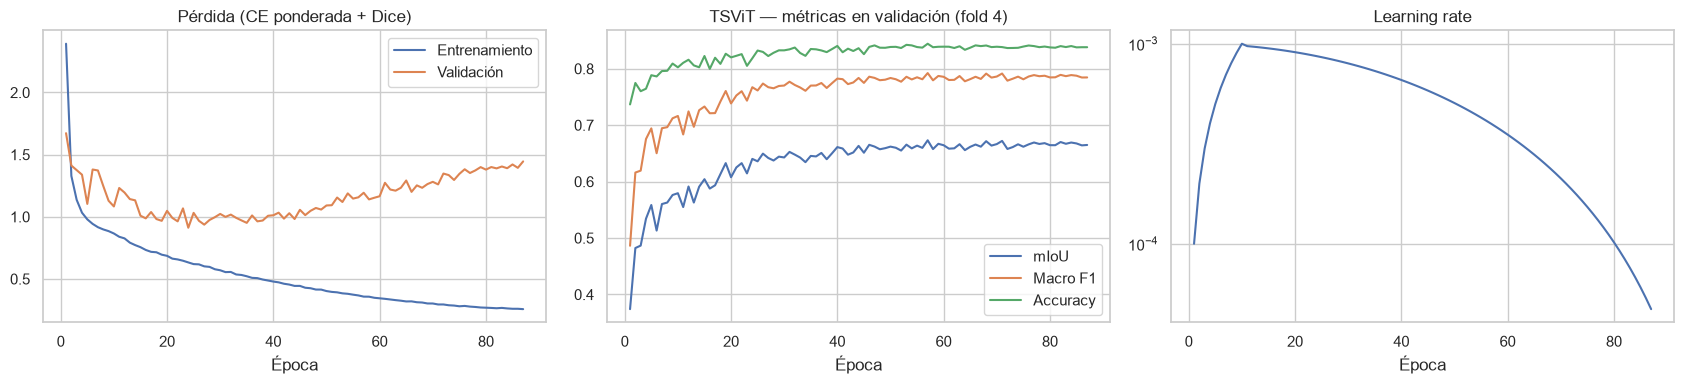

Tiempo medio por época: 15.3 min | total: 22.2 h | mejor época: 57


In [ ]:
# ==============================================================================
# 5.3 CURVAS DE ENTRENAMIENTO
# ==============================================================================
h = pd.DataFrame(historial)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(h.epoca, h.loss_train, label="Entrenamiento"); ax[0].plot(h.epoca, h.loss_val, label="Validación")
ax[0].set(title="Pérdida (CE ponderada + Dice)", xlabel="Época"); ax[0].legend()
ax[1].plot(h.epoca, h.val_miou, label="mIoU"); ax[1].plot(h.epoca, h.val_f1, label="Macro F1")
ax[1].plot(h.epoca, h.val_acc, label="Accuracy")
ax[1].set(title="TSViT — métricas en validación (fold 4)", xlabel="Época"); ax[1].legend()
ax[2].plot(h.epoca, h.lr); ax[2].set(title="Learning rate", xlabel="Época"); ax[2].set_yscale("log")
plt.tight_layout(); plt.show()
print(f"Tiempo medio por época: {h.seg.mean() / 60:.1f} min | total: {h.seg.sum() / 3600:.1f} h | "
      f"mejor época: {int(h.loc[h.val_miou.idxmax(), 'epoca'])}")

### 5.4 Interpretación del Entrenamiento

Las curvas permiten revisar si la pérdida de validación se separa de la de entrenamiento (sobreajuste) y en qué época se alcanza el máximo de mIoU de validación, que define `best.pt`. A diferencia de U-TAE, TSViT tiene un calentamiento de 10 épocas: durante ese tramo el mIoU puede crecer lentamente sin que indique un problema. La pérdida de entrenamiento se calcula sobre ventanas aumentadas y la de validación sobre parches completos reconstruidos, por lo que sus valores absolutos no son directamente comparables.

## 6. Validación (fold 4) y Fijación de la Configuración

Todo lo que se decide en esta sección usa **solo el fold 4**:

1. **TSViT desde cero:** mejor checkpoint y si se usa TTA (promedio sobre las 8 rotaciones/giros), con el mismo criterio que U-TAE en el Avance 6.
2. **TSViT oficial:** control de que los pesos cargados son los correctos —la rejilla original debe reproducir el mIoU registrado por los autores en sus archivos de *tensorboard* (0.6662 en el paso 126,000)— y evaluación con la configuración fijada en la Fase 1 con el fold 4 (ventanas solapadas, 60 fechas, sin TTA porque el modelo se entrenó sin aumentación).
3. **U-TAE:** se usa el checkpoint y la inferencia (TTA) elegidos en el Avance 6; no se vuelve a decidir nada.

In [ ]:
# ==============================================================================
# 6.1 TSViT DESDE CERO: MEJOR CHECKPOINT Y DECISIÓN SOBRE TTA
# ==============================================================================
ck = torch.load(best_path, map_location=DEVICE, weights_only=False)
model = crear_tsvit().to(DEVICE); model.load_state_dict(ck["model"]); model.eval()
print(f"Mejor checkpoint: época {ck['epoca'] + 1} | mIoU de validación registrado: {ck['miou']:.4f}")

res_val_cero = evaluar_tsvit(model, IDS["val"], "Validación")
USAR_TTA_TSVIT = False
filas = [{"Inferencia": "Una pasada", "Accuracy": res_val_cero["Accuracy"], "Macro F1": res_val_cero["Macro F1"],
          "mIoU": res_val_cero["mIoU"]}]
if PROBAR_TTA:
    _r = evaluar_tsvit(model, IDS["val"], "Validación + TTA", tta=True)
    filas.append({"Inferencia": "TTA (8 transformaciones)", "Accuracy": _r["Accuracy"], "Macro F1": _r["Macro F1"],
                  "mIoU": _r["mIoU"]})
    if _r["mIoU"] > res_val_cero["mIoU"]:
        USAR_TTA_TSVIT, res_val_cero = True, _r
display(pd.DataFrame(filas).round(4))
print("Inferencia elegida con validación para TSViT desde cero:", "TTA" if USAR_TTA_TSVIT else "una pasada")

Mejor checkpoint: época 57 | mIoU de validación registrado: 0.6732


Validación:   0%|          | 0/482 [00:00<?, ?it/s]

Validación + TTA:   0%|          | 0/482 [00:00<?, ?it/s]

,Inferencia,Accuracy,Macro F1,mIoU
0,Una pasada,0.8442,0.7923,0.6732
1,TTA (8 transformaciones),0.8452,0.7932,0.6744


Inferencia elegida con validación para TSViT desde cero: TTA


In [ ]:
# ==============================================================================
# 6.2 TSViT OFICIAL: CONTROL CONTRA LOS REGISTROS DE LOS AUTORES (FOLD 4)
# ==============================================================================
model_of = TSViT(dict(CONFIG_TSVIT, legacy_reshape=True)).to(DEVICE)
model_of.load_state_dict(torch.load(RUTA_TSVIT_OFICIAL, map_location="cpu", weights_only=True), strict=True)
model_of.eval()

res_of_rejilla = evaluar_modelo(lambda p: probs_tsvit_oficial(model_of, p, OFFSETS_REJILLA), IDS["val"], "Oficial, rejilla")
res_val_of = evaluar_modelo(lambda p: probs_tsvit_oficial(model_of, p, OFFSETS_SOLAPE), IDS["val"], "Oficial, solape")
display(pd.DataFrame([
    {"Evaluación (fold 4)": "Registro de los autores (tensorboard, paso 126,000)", "Accuracy": 0.8373, "mIoU": 0.6662},
    {"Evaluación (fold 4)": "Rejilla PASTIS24, región 120×120 (este notebook)",
     "Accuracy": res_of_rejilla["r120"]["Accuracy"], "mIoU": res_of_rejilla["r120"]["mIoU"]},
    {"Evaluación (fold 4)": "Ventanas solapadas, parche completo (configuración fijada)",
     "Accuracy": res_val_of["Accuracy"], "mIoU": res_val_of["mIoU"]}]).round(4))
if not MODO_RAPIDO:
    assert abs(res_of_rejilla["r120"]["mIoU"] - 0.6662) < 2e-3, "Los pesos oficiales no reproducen sus registros"
    print("Control superado: la rejilla original reproduce el mIoU registrado por los autores.")

Oficial, rejilla:   0%|          | 0/482 [00:00<?, ?it/s]

Oficial, solape:   0%|          | 0/482 [00:00<?, ?it/s]

,Evaluación (fold 4),Accuracy,mIoU
0,"Registro de los autores (tensorboard, paso 126...",0.8373,0.6662
1,"Rejilla PASTIS24, región 120×120 (este notebook)",0.8373,0.6662
2,"Ventanas solapadas, parche completo (configura...",0.8413,0.6669


Control superado: la rejilla original reproduce el mIoU registrado por los autores.


In [ ]:
# ==============================================================================
# 6.3 U-TAE (AVANCE 6): CARGA DEL CHECKPOINT
# ==============================================================================
model_utae = crear_utae().to(DEVICE); model_utae.load_state_dict(ck_utae["model"]); model_utae.eval()
USAR_TTA_UTAE = True      # decisión tomada con el fold 4 en el Avance 6 (mIoU 0.6499 -> 0.6507)
print(f"U-TAE: mejor época {ck_utae['epoca'] + 1} | mIoU de validación registrado {ck_utae['miou']:.4f} | "
      f"inferencia: {'TTA' if USAR_TTA_UTAE else 'una pasada'}")

U-TAE: mejor época 99 | mIoU de validación registrado 0.6499 | inferencia: TTA


## 7. Evaluación con Datos No Vistos (fold 5) y Comparación

Con las tres configuraciones fijas, el fold 5 se evalúa **una sola vez** para cada modelo, sobre los mismos 496 parches. U-TAE se vuelve a evaluar aquí con su checkpoint y su inferencia del Avance 6 para disponer de las matrices de confusión por parche; su resultado debe coincidir con el reportado en el Avance 6 (mIoU 0.6424).

In [ ]:
# ==============================================================================
# 7.1 MÉTRICAS DE LOS TRES MODELOS EN EL FOLD 5
# ==============================================================================
EJECUTAR_PRUEBA = EVALUAR_PRUEBA and ENTRENAMIENTO_COMPLETO
if not EJECUTAR_PRUEBA:
    raise RuntimeError("Prueba NO evaluada: el entrenamiento de TSViT no ha terminado o EVALUAR_PRUEBA=False.")

ids_test = IDS["test"]
ids_demo = ids_test[:: max(1, len(ids_test) // 4)][:4]          # mismos parches visuales que el Avance 6
RES = {}
RES["U-TAE"] = evaluar_modelo(lambda p: probs_utae(model_utae, p, USAR_TTA_UTAE), ids_test, "Prueba U-TAE", ids_demo)
RES["TSViT (pesos oficiales)"] = evaluar_modelo(lambda p: probs_tsvit_oficial(model_of, p, OFFSETS_SOLAPE),
                                                ids_test, "Prueba TSViT oficial", ids_demo)
RES["TSViT (desde cero)"] = evaluar_tsvit(model, ids_test, "Prueba TSViT desde cero", USAR_TTA_TSVIT, ids_demo)
MODELOS = list(RES)
np.savez_compressed(WORK_DIR / ("confusiones_prueba_rapido.npz" if MODO_RAPIDO else "confusiones_prueba.npz"),
                    ids=np.array(ids_test),
                    **{"".join(ch if ch.isalnum() else "_" for ch in f"{m}_{r}"): RES[m][f"conf{r}_parche"]
                       for m in MODELOS for r in ("128", "120")})

if not MODO_RAPIDO:
    print(f"U-TAE recalculado: mIoU {RES['U-TAE']['mIoU']:.4f} (Avance 6: 0.6424) | "
          f"Macro F1 {RES['U-TAE']['Macro F1']:.4f} (0.7703) | Accuracy {RES['U-TAE']['Accuracy']:.4f} (0.8290)")
    assert abs(RES["U-TAE"]["mIoU"] - 0.6424) < 2e-3, "U-TAE no reproduce el resultado del Avance 6"

Prueba U-TAE:   0%|          | 0/496 [00:00<?, ?it/s]

Prueba TSViT oficial:   0%|          | 0/496 [00:00<?, ?it/s]

Prueba TSViT desde cero:   0%|          | 0/496 [00:00<?, ?it/s]

U-TAE recalculado: mIoU 0.6424 (Avance 6: 0.6424) | Macro F1 0.7703 (0.7703) | Accuracy 0.8290 (0.8290)


In [ ]:
# ==============================================================================
# 7.2 TABLA COMPARATIVA: MÉTRICAS, PARÁMETROS Y TIEMPO DE ENTRENAMIENTO
# ==============================================================================
h_utae = pd.read_csv(RUTA_AVANCE6 / "historial_entrenamiento.csv")
PARAMS = {"U-TAE": sum(p.numel() for p in model_utae.parameters()),
          "TSViT (pesos oficiales)": sum(p.numel() for p in model_of.parameters()),
          "TSViT (desde cero)": sum(p.numel() for p in model.parameters())}
TIEMPO = {"U-TAE": f"{h_utae.seg.sum() / 3600:.1f} h ({len(h_utae)} épocas, RTX 4050)",
          "TSViT (pesos oficiales)": "no disponible (entrenado por los autores)",
          "TSViT (desde cero)": f"{pd.DataFrame(historial).seg.sum() / 3600:.1f} h ({len(historial)} épocas, RTX 4050)"}
tabla = pd.DataFrame([{
    "Modelo": m, "Accuracy": RES[m]["Accuracy"], "Macro F1": RES[m]["Macro F1"], "mIoU": RES[m]["mIoU"],
    "mIoU 120×120": RES[m]["r120"]["mIoU"], "Parámetros": f"{PARAMS[m]:,}", "Entrenamiento": TIEMPO[m]}
    for m in MODELOS])
print("=== FOLD 5 — PARCHES COMPLETOS (128×128) Y REGIÓN COMÚN (120×120) ===")
display(tabla.round(4))

=== FOLD 5 — PARCHES COMPLETOS (128×128) Y REGIÓN COMÚN (120×120) ===


,Modelo,Accuracy,Macro F1,mIoU,mIoU 120×120,Parámetros,Entrenamiento
0,U-TAE,0.8290,0.7703,0.6424,0.6435,"1,086,969","10.1 h (100 épocas, RTX 4050)"
1,TSViT (pesos oficiales),0.8337,0.7745,0.6509,0.6529,"1,657,476",no disponible (entrenado por los autores)
2,TSViT (desde cero),0.8378,0.7807,0.6587,0.6614,"1,665,668","22.2 h (87 épocas, RTX 4050)"


,Clase,Soporte (px),IoU U-TAE,IoU TSViT (pesos oficiales),IoU TSViT (desde cero),Δ IoU cero − U-TAE
0,Fondo,3221643,0.7327,0.7372,0.7429,0.0102
1,Pradera,1487831,0.6458,0.6379,0.6496,0.0038
2,Trigo blando de invierno,580631,0.8636,0.8802,0.8756,0.0121
3,Maíz,620357,0.8622,0.8715,0.8666,0.0044
4,Cebada de invierno,171711,0.8054,0.8307,0.8150,0.0096
5,Colza de invierno,157965,0.8792,0.9013,0.9004,0.0211
6,Cebada de primavera,55308,0.5717,0.6252,0.6210,0.0492
7,Girasol,90899,0.6987,0.7055,0.7092,0.0105
8,Vid,219555,0.5859,0.5091,0.5887,0.0028
9,Remolacha,67567,0.8459,0.8680,0.8789,0.0329


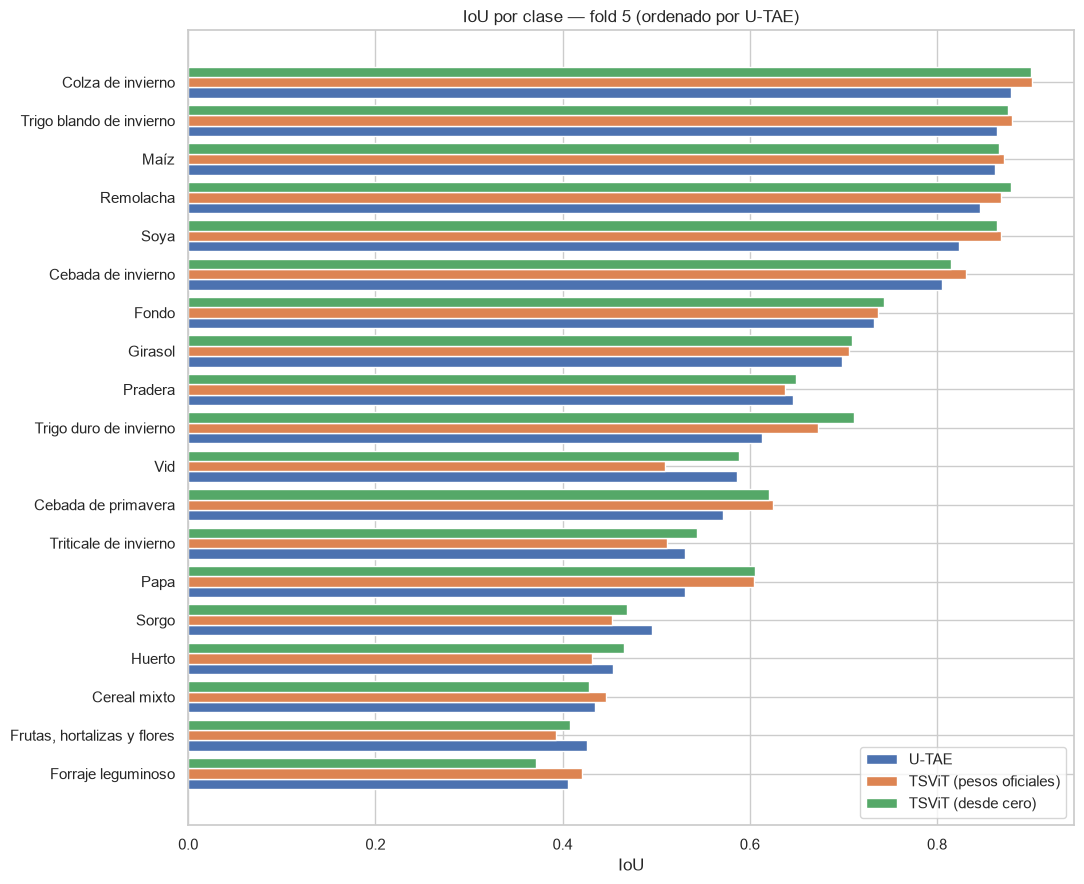

In [ ]:
# ==============================================================================
# 7.3 IoU POR CLASE EN EL FOLD 5
# ==============================================================================
por_clase = pd.DataFrame({"Clase": [NOMBRES_CLASES[i] for i in range(NUM_CLASSES)],
                          "Soporte (px)": RES["U-TAE"]["conf"].sum(1).astype(int),
                          **{f"IoU {m}": RES[m]["iou"].round(4) for m in MODELOS}})
por_clase["Δ IoU cero − U-TAE"] = (RES["TSViT (desde cero)"]["iou"] - RES["U-TAE"]["iou"]).round(4)
display(por_clase)

orden = np.argsort(RES["U-TAE"]["iou"])
fig, ax = plt.subplots(figsize=(11, 9))
alto = 0.27
for j, m in enumerate(MODELOS):
    ax.barh(np.arange(NUM_CLASSES) + (j - 1) * alto, RES[m]["iou"][orden], height=alto, label=m)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels([NOMBRES_CLASES[i] for i in orden])
ax.set(title="IoU por clase — fold 5 (ordenado por U-TAE)", xlabel="IoU"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

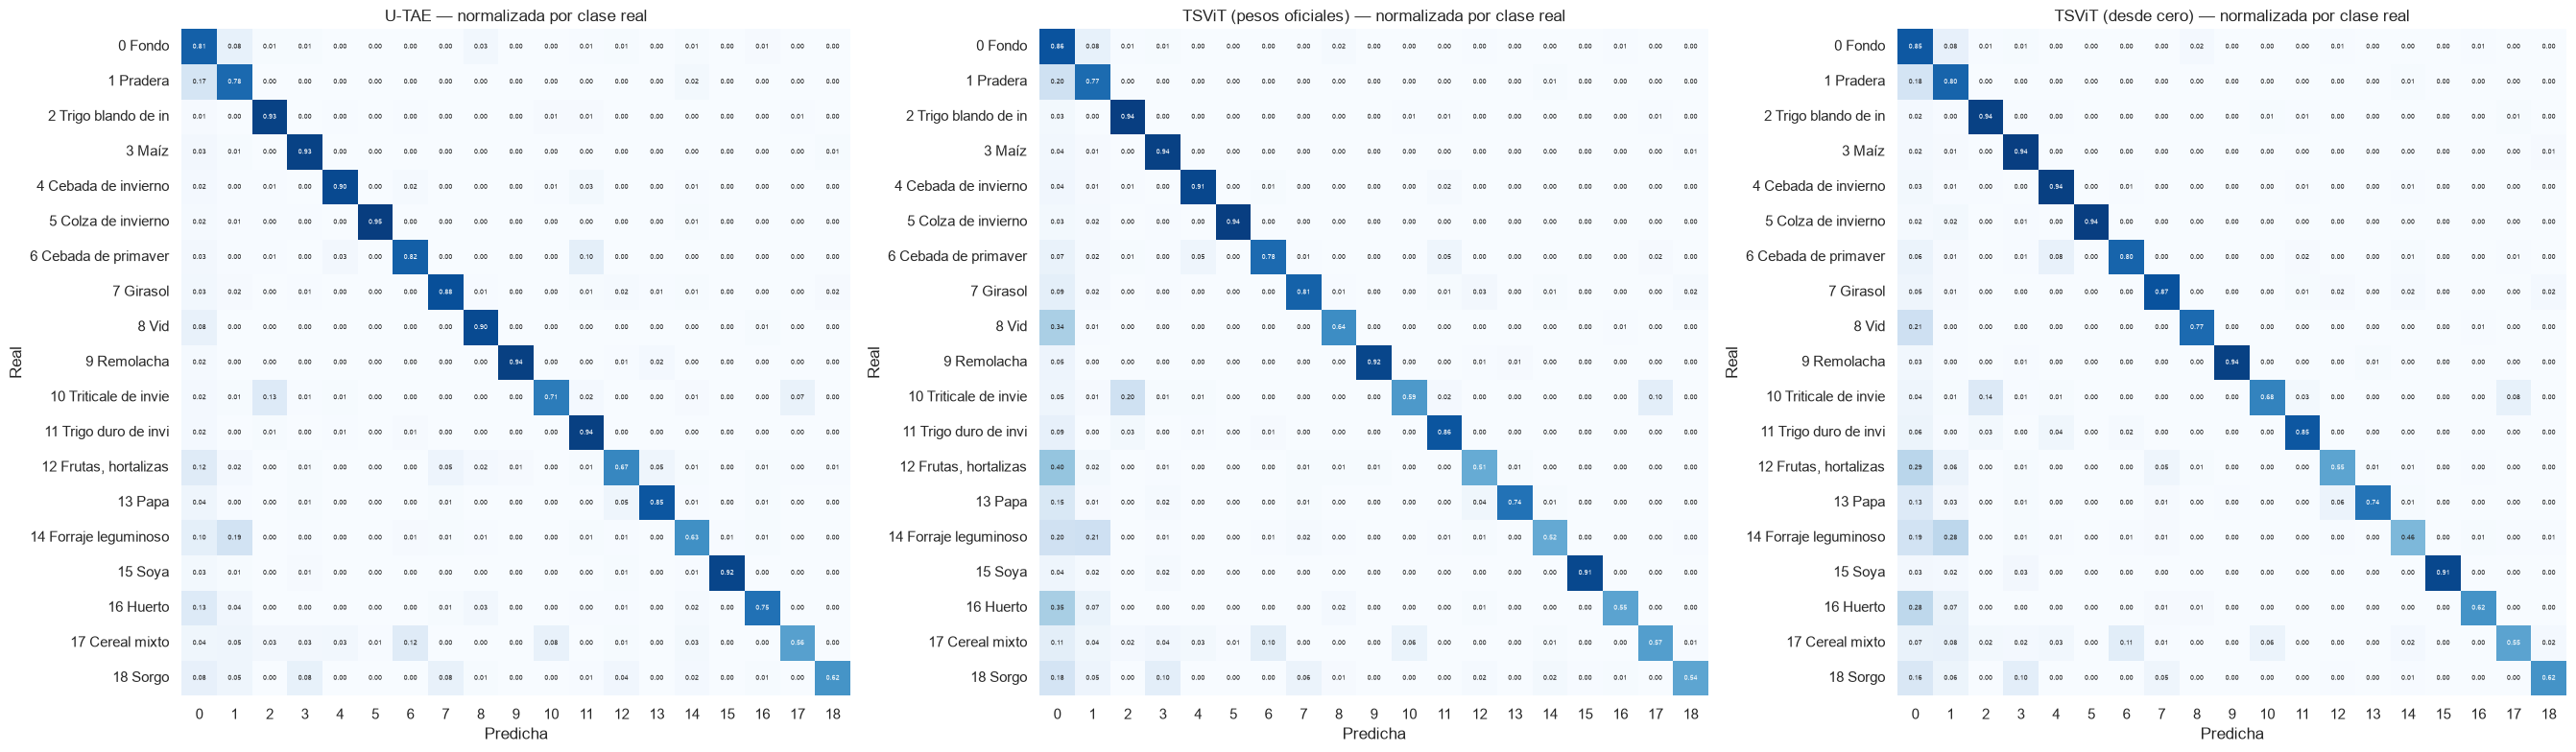

In [ ]:
# ==============================================================================
# 7.4 MATRICES DE CONFUSIÓN NORMALIZADAS (FOLD 5)
# ==============================================================================
fig, ax = plt.subplots(1, 3, figsize=(27, 8))
for a, m in zip(ax, MODELOS):
    conf = RES[m]["conf"]; norm = conf / np.maximum(conf.sum(1, keepdims=True), 1)
    sns.heatmap(norm, ax=a, cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 5}, cbar=False,
                xticklabels=range(NUM_CLASSES), yticklabels=[f"{i} {NOMBRES_CLASES[i][:18]}" for i in range(NUM_CLASSES)])
    a.set(title=f"{m} — normalizada por clase real", xlabel="Predicha", ylabel="Real")
plt.tight_layout(); plt.show()

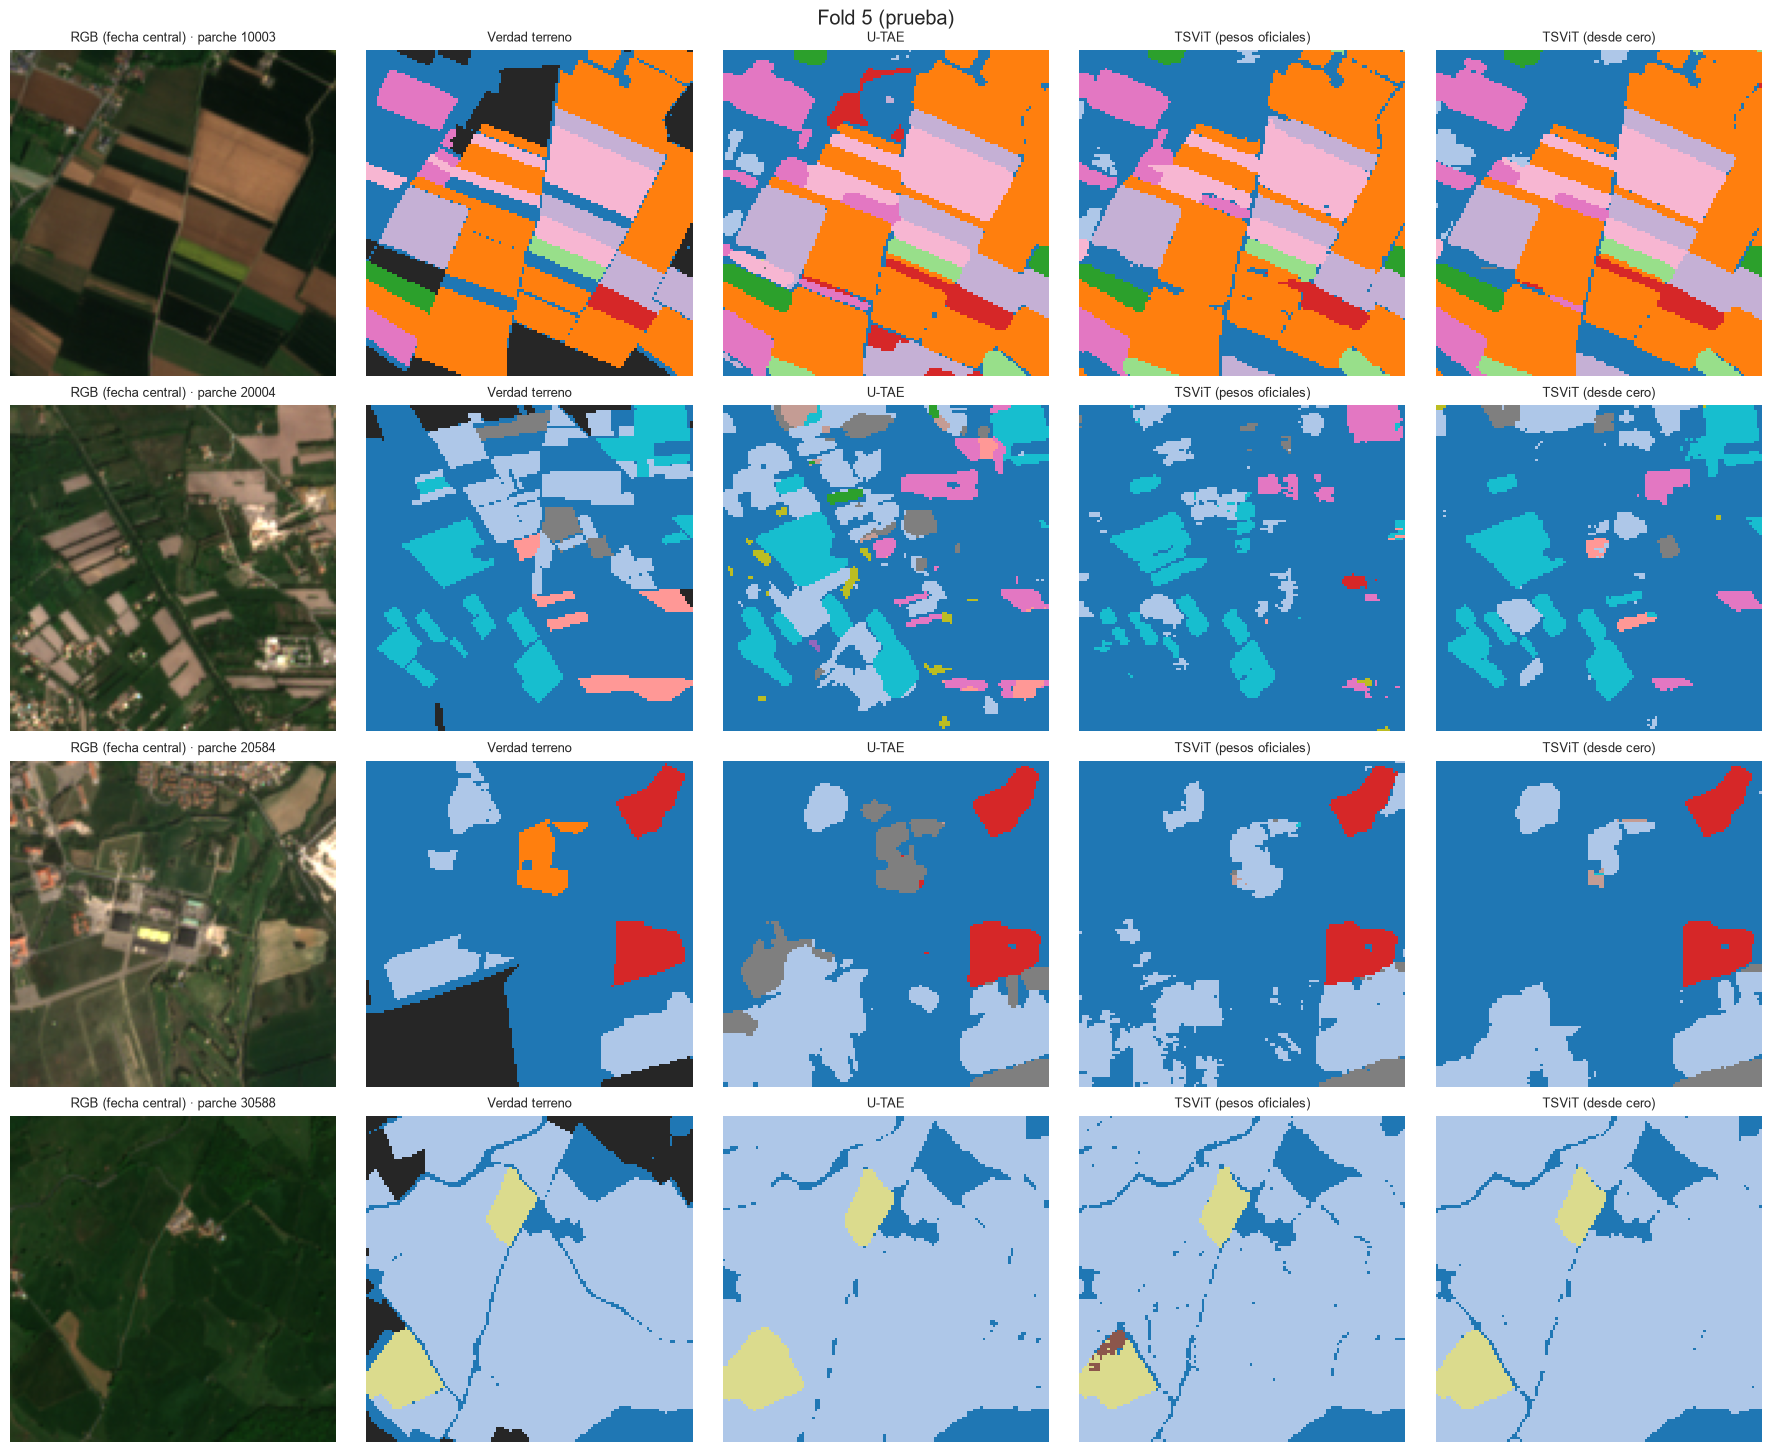

In [ ]:
# ==============================================================================
# 7.5 EJEMPLOS CUALITATIVOS SOBRE LOS MISMOS PARCHES
# ==============================================================================
from matplotlib.colors import ListedColormap
colores = plt.get_cmap("tab20")(np.linspace(0, 1, 20)); colores[19] = (0.15, 0.15, 0.15, 1)
cmap = ListedColormap(colores)
fig, ax = plt.subplots(len(ids_demo), 5, figsize=(18, 3.7 * len(ids_demo)))
ax = np.atleast_2d(ax)
for fila, pid in enumerate(ids_demo):
    bruto = np.load(ruta_s2(pid), mmap_mode="r")[len(DATES[pid]) // 2].astype(np.float32)
    ax[fila, 0].imshow(np.clip(bruto[[2, 1, 0]].transpose(1, 2, 0) / 3000, 0, 1))
    ax[fila, 1].imshow(np.load(ruta_target(pid))[0], cmap=cmap, vmin=0, vmax=19, interpolation="nearest")
    for j, m in enumerate(MODELOS):
        ax[fila, 2 + j].imshow(RES[m]["preds"][pid], cmap=cmap, vmin=0, vmax=19, interpolation="nearest")
    for j, t in enumerate(["RGB (fecha central)", "Verdad terreno"] + MODELOS):
        ax[fila, j].set_title(f"{t} · parche {pid}" if j == 0 else t, fontsize=9); ax[fila, j].axis("off")
plt.suptitle("Fold 5 (prueba)" if not MODO_RAPIDO else "Prueba de humo (fold 4)")
plt.tight_layout(); plt.show()

### 7.6 Intervalos de confianza bootstrap por parche

Las diferencias de mIoU entre modelos se acompañan de un intervalo bootstrap: se remuestrean con reemplazo los **496 parches** del fold 5 (`N_BOOTSTRAP` réplicas, semilla 42), se suman sus matrices de confusión y se recalcula el mIoU de cada modelo con **las mismas réplicas** para los tres, de modo que el intervalo refleja la variabilidad debida a qué parches forman la prueba. Remuestrear parches y no píxeles respeta que los píxeles de un mismo parche están correlacionados.

Este intervalo **no** incluye la variabilidad entre entrenamientos (semillas), porque cada modelo se entrenó una sola vez.

,Diferencia,Δ mIoU observado,IC 95% inferior,IC 95% superior,P(Δ > 0),¿El IC incluye 0?
0,TSViT (desde cero) − U-TAE,0.0163,0.0064,0.0263,1.0000,no
1,TSViT (pesos oficiales) − U-TAE,0.0085,-0.0006,0.0177,0.9625,sí
2,TSViT (desde cero) − TSViT (pesos oficiales),0.0078,-0.0018,0.0180,0.9380,sí


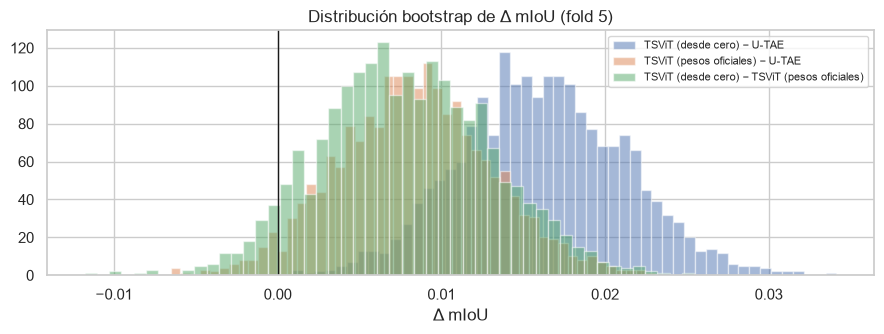

In [ ]:
# ==============================================================================
# 7.6 BOOTSTRAP POR PARCHE DE LAS DIFERENCIAS DE mIoU
# ==============================================================================
def miou_desde_lote(conf):          # conf: (R, 19, 19)
    tp = np.diagonal(conf, axis1=1, axis2=2); real = conf.sum(2); pred = conf.sum(1)
    union = real + pred - tp
    return np.where(union > 0, tp / np.maximum(union, 1), 0.0).mean(1)

rng_bs = np.random.default_rng(SEED)
n = len(ids_test)
pesos_bs = np.stack([np.bincount(rng_bs.integers(0, n, n), minlength=n) for _ in range(N_BOOTSTRAP)]).astype(np.float64)
MIOU_BS = {m: miou_desde_lote(np.tensordot(pesos_bs, RES[m]["conf128_parche"].astype(np.float64), axes=1))
           for m in MODELOS}
pares = [("TSViT (desde cero)", "U-TAE"), ("TSViT (pesos oficiales)", "U-TAE"),
         ("TSViT (desde cero)", "TSViT (pesos oficiales)")]
filas_bs = []
for a, b in pares:
    dif = MIOU_BS[a] - MIOU_BS[b]
    lo, hi = np.percentile(dif, [2.5, 97.5])
    filas_bs.append({"Diferencia": f"{a} − {b}", "Δ mIoU observado": RES[a]["mIoU"] - RES[b]["mIoU"],
                     "IC 95% inferior": lo, "IC 95% superior": hi, "P(Δ > 0)": (dif > 0).mean(),
                     "¿El IC incluye 0?": "sí" if lo <= 0 <= hi else "no"})
TABLA_BS = pd.DataFrame(filas_bs)
display(TABLA_BS.round(4))
fig, ax = plt.subplots(figsize=(9, 3.5))
for a, b in pares:
    ax.hist(MIOU_BS[a] - MIOU_BS[b], bins=50, alpha=0.5, label=f"{a} − {b}")
ax.axvline(0, color="k", lw=1); ax.set(title="Distribución bootstrap de Δ mIoU (fold 5)", xlabel="Δ mIoU"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7.7 Interpretación de la Evaluación

- **Tabla 7.2:** la columna `mIoU` (parche completo) es la comparación principal, con los mismos píxeles que el Avance 6. La columna `mIoU 120×120` permite ver si la diferencia depende de los bordes del parche, que el benchmark PASTIS24 nunca evalúa.
- **TSViT oficial frente a TSViT desde cero:** no difieren solo en quién los entrenó. El oficial usa día del año, normalización fija, cross-entropy sin pesos, sin aumentación y la reconstrucción espacial antigua; el entrenado aquí usa días desde 2018-09-01 y el pipeline del Avance 6. Su diferencia no puede atribuirse a un solo factor.
- **TSViT desde cero frente a U-TAE:** es la comparación más controlada (misma partición, normalización, pérdida, pesos de clase, aumentación, criterio de selección y referencia temporal); aun así cambian el tamaño de entrada (ventanas de 24×24 frente a parches de 128×128), el número de parámetros y los hiperparámetros de optimización, que se tomaron de cada artículo.
- **Bootstrap (7.6):** una diferencia cuyo intervalo incluye 0 no permite afirmar que un modelo sea mejor que otro en este conjunto de prueba.

## 8. Conclusiones Metodológicas CRISP-ML(Q)

### Procedimiento
Se compararon tres modelos sobre las mismas particiones oficiales y las mismas métricas: U-TAE (Avance 6), TSViT con los pesos publicados por sus autores y TSViT entrenado desde cero con el pipeline del Avance 6. Antes de evaluar se verificó que el checkpoint oficial correspondía a la partición folds 1–3 / 4 / 5 y que, con la reconstrucción espacial original, reproduce exactamente las métricas registradas por los autores en el fold 4. Todas las decisiones de inferencia (ventanas solapadas, longitud de la serie, TTA) se tomaron con el fold 4; el fold 5 se evaluó una sola vez por modelo.

### Criterios de evaluación
Se reporta el mIoU sobre parches completos como métrica principal, junto con Macro F1 y Accuracy, el IoU por clase y la matriz de confusión. Las diferencias entre modelos se acompañan de intervalos bootstrap por parche.

### Limitaciones
- **Una sola semilla y una sola corrida por modelo:** las diferencias de 1–2 puntos de mIoU están dentro de lo que puede variar entre entrenamientos y no deben sobreinterpretarse; el bootstrap solo cubre la variabilidad de los parches de prueba.
- **TSViT desde cero no es exactamente el TSViT publicado:** usa días desde 2018-09-01 en lugar del día del año, la reconstrucción espacial corregida, la pérdida y los pesos de clase del Avance 6, aumentación D4 con ventanas en posición aleatoria, recorte de gradiente y selección por época sobre parches completos.
- **Codificación temporal del TSViT oficial:** el día del año asigna el mismo código a fechas de 2018 y 2019 en todos los parches de PASTIS, lo que limita la información temporal que recibe ese modelo.
- **Comparación con el artículo:** los autores promedian los 5 folds y evalúan sobre la rejilla de 120×120; aquí se usa un único fold de prueba y el parche completo.
- **Solo Sentinel-2** y sin búsqueda sistemática de hiperparámetros, como en el Avance 6.

### Posibles extensiones
Varias semillas por modelo, una ablación de TSViT con día del año frente a días desde 2018-09-01, la variante TSViT-S (0.44 M parámetros) y la fusión con Sentinel-1.

La siguiente celda resume los resultados de esta misma ejecución.

In [ ]:
# ==============================================================================
# 8.1 SÍNTESIS CUANTITATIVA DE ESTA EJECUCIÓN
# ==============================================================================
def fila(m):
    return f"mIoU = **{RES[m]['mIoU']:.4f}**, Macro F1 = **{RES[m]['Macro F1']:.4f}**, Accuracy = **{RES[m]['Accuracy']:.4f}**"

texto = f"""
**Síntesis de esta ejecución (fold 5, parches completos).**

- **U-TAE (Avance 6):** {fila('U-TAE')}.
- **TSViT (pesos oficiales):** {fila('TSViT (pesos oficiales)')}.
- **TSViT (desde cero):** {fila('TSViT (desde cero)')} (mejor época {ck['epoca'] + 1}; inferencia {'TTA' if USAR_TTA_TSVIT else 'una pasada'}).

**Diferencias de mIoU con intervalo bootstrap al 95 % ({N_BOOTSTRAP} réplicas por parche):**
"""
for _, f in TABLA_BS.iterrows():
    concl = ("el intervalo incluye 0: no hay evidencia de diferencia" if f["¿El IC incluye 0?"] == "sí"
             else ("el intervalo es positivo" if f["IC 95% inferior"] > 0 else "el intervalo es negativo"))
    texto += (f"\n- {f['Diferencia']}: **{f['Δ mIoU observado']:+.4f}** "
              f"[{f['IC 95% inferior']:+.4f}, {f['IC 95% superior']:+.4f}] — {concl}.")
texto += ("\n\nEl artículo de TSViT reporta unos 2 puntos de ventaja sobre U-TAE. Con una sola corrida por modelo, "
          "estos resultados no confirman ni descartan esa diferencia por sí solos; se interpretan junto con el IoU "
          "por clase y las limitaciones de la sección 8.")
if MODO_RAPIDO:
    texto += "\n\n**Atención:** ejecución en MODO_RAPIDO (prueba de humo); estas cifras no son resultados de los modelos."
display(Markdown(texto))


**Síntesis de esta ejecución (fold 5, parches completos).**

- **U-TAE (Avance 6):** mIoU = **0.6424**, Macro F1 = **0.7703**, Accuracy = **0.8290**.
- **TSViT (pesos oficiales):** mIoU = **0.6509**, Macro F1 = **0.7745**, Accuracy = **0.8337**.
- **TSViT (desde cero):** mIoU = **0.6587**, Macro F1 = **0.7807**, Accuracy = **0.8378** (mejor época 57; inferencia TTA).

**Diferencias de mIoU con intervalo bootstrap al 95 % (2000 réplicas por parche):**

- TSViT (desde cero) − U-TAE: **+0.0163** [+0.0064, +0.0263] — el intervalo es positivo.
- TSViT (pesos oficiales) − U-TAE: **+0.0085** [-0.0006, +0.0177] — el intervalo incluye 0: no hay evidencia de diferencia.
- TSViT (desde cero) − TSViT (pesos oficiales): **+0.0078** [-0.0018, +0.0180] — el intervalo incluye 0: no hay evidencia de diferencia.

El artículo de TSViT reporta unos 2 puntos de ventaja sobre U-TAE. Con una sola corrida por modelo, estos resultados no confirman ni descartan esa diferencia por sí solos; se interpretan junto con el IoU por clase y las limitaciones de la sección 8.

### Referencias

- Tarasiou, M., Chavez, E., & Zafeiriou, S. (2023). *ViTs for SITS: Vision Transformers for Satellite Image Time Series*. CVPR, 10418–10428. Código y pesos: https://github.com/michaeltrs/DeepSatModels (licencia Apache 2.0).
- Garnot, V. S. F., & Landrieu, L. (2021). *Panoptic Segmentation of Satellite Image Time Series with Convolutional Temporal Attention Networks*. ICCV. Código: https://github.com/VSainteuf/utae-paps (licencia MIT).

## Declaración sobre el uso de herramientas de inteligencia artificial

**Equipo:** 13  
**Integrantes:**
- José Eduardo De Moraes López - A01634782
- André Zaragoza Bonilla - A01797076
- David Alejandro Velázquez Valdéz - A01632648

**Actividad:** Avance 7. Comparación de U-TAE y TSViT  

**Herramientas de IA utilizadas:** Claude (Anthropic, Claude Code, 2026) *(agregar Gemini u otra herramienta si también se utilizó en revisión o redacción)*.

**Uso declarado:**
- Revisión del código y la configuración del repositorio oficial de TSViT (construcción de `PASTIS24`, *folds* de cada *checkpoint*, normalización y codificación de fechas).
- Integración de TSViT en el *notebook* (con la variante de fechas y la atención fusionada documentadas en la sección 3), generación de ventanas al vuelo, *benchmark* de velocidad, bucle de entrenamiento con *checkpoints* y análisis *bootstrap*.
- Apoyo en la redacción y estructuración de las explicaciones metodológicas.

**Verificación y responsabilidad del equipo:**
- Las decisiones de diseño (partición, comparación con pesos oficiales y desde cero, codificación temporal, función de pérdida y criterio de selección) fueron revisadas y aprobadas por el equipo.
- La ejecución con los datos reales, la verificación de las métricas y las conclusiones son responsabilidad académica exclusiva de los integrantes del equipo.

**Contribución individual del equipo:**
- **José Eduardo De Moraes López:** [Ej. Implementación e integración de la arquitectura TSViT, adaptación de la codificación temporal y ejecución del entrenamiento desde cero].
- **André Zaragoza Bonilla:** [Ej. Validación de particiones de PASTIS, evaluación de pesos oficiales (`TSViT_fold1`) y diagnóstico de reconstrucción espacial.
- **David Alejandro Velázquez Valdéz:** [Ej. Implementación del *benchmark* de velocidad, análisis estadístico *bootstrap*, visualización de resultados y redacción metodológica].

**Decisiones principales:**
- **Pesos oficiales:** se usó únicamente el *checkpoint* `TSViT_fold1` publicado por los autores (entrenamiento en *folds* 1–3, validación en 4, prueba en 5). Se descartó un *checkpoint* entrenado anteriormente por el equipo porque sus *folds* se generaron con una partición aleatoria y había visto parches del *fold* 5.
- **Codificación temporal:** el TSViT entrenado desde cero usa días transcurridos desde `2018-09-01` para recibir exactamente la misma información temporal que U-TAE.
- **Selección y evaluación:** se seleccionó el mejor *checkpoint* con base en el `mIoU` de validación, reservando el *fold* 5 exclusivamente para la evaluación final de los tres modelos.